# Predicción de churn en una entidad financiera

**Curso:** Métodos y Aplicaciones de Analítica II, Pontificia Universidad Javeriana. **Equipo:** Juan Fernando Rengifo y Juan Diego Díaz.

El notebook sigue el ciclo CRISP-DM. La lógica vive en `src/churn/`: aquí se llama, se muestran los resultados y se toman las decisiones.

| Fase | Pregunta que responde | Secciones |
|---|---|---|
| 1. Comprensión del negocio | ¿Qué decide el banco y cómo se mide? | 1.1 a 1.3 |
| 2. Comprensión de los datos | ¿Son confiables y qué señales traen? | 2.1 a 2.9 |
| 3. Preparación de los datos | ¿Cómo se preparan sin fuga? | 3.1 y 3.2 |
| 4. Modelado | ¿Qué modelo ordena mejor? | 4.1 a 4.8 |
| 5. Evaluación | ¿Funciona con clientes nuevos y conviene? | 5.1 a 5.9 |
| 6. Despliegue, monitoreo y control | ¿Cómo se usa y se vigila? | 6.1 a 6.4 |

## Preparación del entorno

Los imports se cargan una sola vez. Rutas, semilla, tamaño del test y pliegues se leen de `src/churn/config.py`.

In [32]:
%matplotlib inline
import platform
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from churn import (comparacion, config, datos, evaluacion, exploracion, explicabilidad, features, graficos,
                   graficos_modelado, graficos_negocio, modelos, monitoreo, negocio, produccion, reportes)

# Semillas fijas: la misma corrida produce siempre los mismos resultados
random.seed(config.SEMILLA)
np.random.seed(config.SEMILLA)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)  # para ver completos los hiperparámetros elegidos

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"SEMILLA = {config.SEMILLA} | TEST_SIZE = {config.TEST_SIZE} | N_PLIEGUES = {config.N_PLIEGUES}")
print(f"Escenarios de capacidad (supuestos): {[f'{k:.0%}' for k in config.ESCENARIOS_CAPACIDAD]}")

Python 3.11.9 | pandas 2.1.4 | numpy 1.26.4
SEMILLA = 42 | TEST_SIZE = 0.2 | N_PLIEGUES = 5
Escenarios de capacidad (supuestos): ['10%', '20%', '30%']


## CRISP-DM Fase 1: Comprensión del negocio

### 1.1 Problema

El banco perdió el 15 % de sus clientes activos en un trimestre y creó un programa de beneficios. No puede ofrecérselo a todos: necesita saber a quién contactar primero.

### 1.2 Objetivo y pregunta

Estimar, con las variables de 2021, la probabilidad de *churn* (que el cliente se vaya) antes del cierre de 2022 y ordenar a los clientes de mayor a menor riesgo. Pregunta: ¿qué modelo ordena mejor y cuántos clientes que se van (*churners*) captura el banco si contacta al 10 %, 20 % o 30 % de mayor riesgo?

### 1.3 Indicadores y supuestos

| Indicador | Pregunta que responde | Dónde |
|---|---|---|
| **AUC** (principal) | ¿El modelo pone primero a quien se va? No depende de un umbral (0,5 es azar) | Fases 4 y 5 |
| **Captura y precisión con 10, 20 y 30 %** | ¿Cuántos churners encuentra el banco y cuántos beneficios van a quien no se iba? Es lo que decide el banco | 5.4 |
| **Precisión marginal** | ¿Conviene ampliar el contacto? Mide lo que encuentran los contactos adicionales | 5.4 y 5.5 |
| AP (AUC-PR) | ¿Ordena bien a la clase minoritaria (16 %)? | Fase 4 |
| Brecha entre train y validación | ¿El modelo memoriza? | Fase 4 |
| Accuracy frente al baseline | ¿Supera a decir que nadie se va? Solo como referencia | 2.1 y 5.1 |
| Sensibilidad, precisión, F1 y matriz de confusión con umbral 0,5 | Vista clásica de clasificación; **no es la regla de operación** | 5.1 |
| Brier y calibración | ¿La probabilidad se puede leer como porcentaje? | 5.3 |
| PSI y captura en un grupo de control | ¿El modelo sigue sirviendo con clientes nuevos? | 6.3 |

No se usa Kappa: con un umbral fijo repite lo que dice el F1, y aquí se decide por capacidad.

**Supuesto de capacidad.** El caso no la informa. Se evalúan 10 % (por debajo de la tasa de churn de 16 %), 20 % (un poco por encima) y 30 % (muy por encima).

## CRISP-DM Fase 2: Comprensión de los datos

### 2.1 Carga, validación y partición

Se carga el archivo sin modificarlo, se valida (si un chequeo falla, el notebook se detiene), se crea el objetivo y se parte 80 % train y 20 % test, de forma aleatoria y estratificada (el archivo no trae fechas; 5.8). **El test no se toca hasta la Fase 5.**

#### Carga de los datos crudos

In [33]:
crudo = datos.cargar_datos()
print(f"Archivo: {config.RUTA_DATOS_CRUDOS.relative_to(config.RAIZ).as_posix()} | filas: {crudo.shape[0]:,} | columnas: {crudo.shape[1]}")

Archivo: data/raw/bank_churn.xlsx | filas: 10,127 | columnas: 21


#### Validación de esquema, calidad y coherencia contable

In [34]:
reporte_validacion = datos.validar_datos(crudo, estricto=True)
print(f"Chequeos superados: {reporte_validacion['cumple'].sum()} de {len(reporte_validacion)}")
display(reporte_validacion)

Chequeos superados: 26 de 26


,chequeo,cumple,detalle
0,Columnas esperadas,True,faltan: ninguna; sobran: ninguna
1,Sin valores faltantes,True,0 celdas vacías
2,Sin filas duplicadas,True,0 filas repetidas
3,Identificador único,True,0 clientnum repetidos
4,Categorías válidas en attrition_flag,True,no esperadas: ninguna
5,Categorías válidas en gender,True,no esperadas: ninguna
6,Categorías válidas en education_level,True,no esperadas: ninguna
7,Categorías válidas en marital_status,True,no esperadas: ninguna
8,Categorías válidas en income_category,True,no esperadas: ninguna
9,Categorías válidas en card_category,True,no esperadas: ninguna


#### Limpieza y creación del objetivo binario

In [35]:
limpio = datos.limpiar_datos(crudo)
display(datos.resumen_variables(limpio))

balance = datos.balance_objetivo(limpio)
display(balance)
baseline = balance.loc[0, "proporcion"]
print(f"Baseline trivial (decir que nadie se va): accuracy de {baseline:.2%} sin detectar a ningún churner")

,tipo,valores_distintos,faltantes,ejemplo
customer_age,int64,45,0,45
gender,object,2,0,M
dependent_count,int64,6,0,3
education_level,object,7,0,High School
marital_status,object,4,0,Married
income_category,object,6,0,$60K - $80K
card_category,object,4,0,Blue
months_on_book,int64,44,0,39
total_relationship_count,int64,6,0,5
months_inactive_12_mon,int64,7,0,1


,clase,clientes,proporcion
churn,,,
0,Se queda (Existing Customer),8500,0.8393
1,Se va (Attrited Customer),1627,0.1607


Baseline trivial (decir que nadie se va): accuracy de 83.93% sin detectar a ningún churner


#### Partición estratificada y guardado de los datos procesados

In [36]:
particion = datos.particionar(limpio)
rutas = datos.guardar_procesado(limpio, particion)
display(particion.resumen())
for nombre, ruta in rutas.items():
    print(f"Guardado ({nombre}): {ruta.relative_to(config.RAIZ).as_posix()}")

,clientes,churners,tasa_churn
conjunto,,,
train,8101,1302,0.1607
test,2026,325,0.1604


Guardado (datos): data/processed/bank_churn_limpio.csv
Guardado (particion): data/processed/particion.csv


#### Lectura y decisión

- **Datos confiables:** 10.127 clientes y 21 columnas, sin vacíos ni duplicados; las identidades contables se cumplen.
- **Desbalance:** 1.627 churners (16,07 %). Decir "nadie se va" acierta 83,93 %: se elige por AUC, no por accuracy.
- **Partición:** 8.101 en train y 2.026 en test, con churn de 16,07 % y 16,04 %.

#### Base del EDA: solo train

El EDA usa los 8.101 clientes de train: mirar el test invalidaría la evaluación. Primero, un barrido automático de todas las variables (2.2); después, análisis dirigido solo donde hay que relacionar con el churn o hay un riesgo para la decisión (2.3 a 2.8).

In [37]:
X_eda, y_eda = particion.X_train, particion.y_train
tasa_global = y_eda.mean()
graficos.aplicar_estilo()
print(f"Clientes para el EDA (train): {len(X_eda):,} | tasa de churn: {tasa_global:.2%}")

Clientes para el EDA (train): 8,101 | tasa de churn: 16.07%


### 2.2 EDA automático de train

`ydata-profiling` revisa las 19 variables: distribuciones, asimetría, atípicos, ceros, valores únicos, correlaciones y asociación entre categóricas. Lo que este barrido resuelve se decide aquí. Lo que exige mirar el churn o implica un riesgo se analiza en 2.3 a 2.8.

In [38]:
alertas = exploracion.perfil_automatico(X_eda, y_eda, config.RAIZ / "reports" / "perfil_train.html")
reportes.guardar_tabla(alertas, "eda_alertas_perfil", decimales=None, indice=False)
print(f"Alertas del EDA automático: {len(alertas)} (reporte completo en reports/perfil_train.html)")
display(alertas.groupby("tipo")["variable"].apply(", ".join).to_frame("variables"))

100%|██████████| 20/20 [00:00<00:00, 175.90it/s]


Alertas del EDA automático: 15 (reporte completo en reports/perfil_train.html)


,variables
tipo,
HIGH_CORRELATION,"avg_open_to_buy, avg_utilization_ratio, credit_limit, customer_age, gender, income_category, months_on_book, total_r..."
IMBALANCE,card_category
ZEROS,"avg_utilization_ratio, contacts_count_12_mon, dependent_count, total_revolving_bal"


In [39]:
resumen_num = exploracion.resumen_numericas(X_eda, y_eda)
reportes.guardar_tabla(resumen_num, "eda_resumen_numericas", decimales=3)
print("Forma de las distribuciones: asimetría y porcentaje de atípicos (rango intercuartílico)")
display(resumen_num[["asimetria", "pct_atipicos_iqr"]].sort_values("asimetria", key=abs, ascending=False).round(2))
print("Pares de variables numéricas con correlación de Spearman de 0,5 o más, en valor absoluto")
display(exploracion.pares_correlacionados(X_eda, umbral=0.5).round(3))

Forma de las distribuciones: asimetría y porcentaje de atípicos (rango intercuartílico)


,asimetria,pct_atipicos_iqr
variable,,
total_ct_chng_q4_q1,2.25,3.91
total_trans_amt,2.05,8.69
total_amt_chng_q4_q1,1.80,3.84
credit_limit,1.68,9.68
avg_open_to_buy,1.68,9.57
avg_utilization_ratio,0.71,0.00
months_inactive_12_mon,0.64,3.27
total_relationship_count,-0.17,0.00
total_revolving_bal,-0.16,0.00


Pares de variables numéricas con correlación de Spearman de 0,5 o más, en valor absoluto


,variable_1,variable_2,correlacion
0,credit_limit,avg_open_to_buy,0.931
1,total_trans_amt,total_trans_ct,0.882
2,customer_age,months_on_book,0.770
3,total_revolving_bal,avg_utilization_ratio,0.709
4,avg_open_to_buy,avg_utilization_ratio,-0.684


#### Lectura y decisión

| Hallazgo del barrido | Evidencia | Decisión |
|---|---|---|
| Colas largas | Cinco variables con asimetría de 1,68 a 2,25 y hasta 9,68 % de atípicos (`credit_limit`); son valores reales, pasaron la validación de rangos | No se recortan: Yeo-Johnson y estandarización en el pipeline de los modelos sensibles a la escala (Fase 3) |
| Redundancia | `avg_open_to_buy` es `credit_limit` menos `total_revolving_bal` (Spearman de 0,931 con el cupo) | **Se elimina `avg_open_to_buy`** |
| Otras correlaciones altas | Monto y número de transacciones (0,882), edad y antigüedad (0,770), saldo y utilización (0,709) | Se conservan porque miden cosas distintas; monto y transacciones se analizan juntas en 2.4 |
| Asociación entre categóricas | `gender` e `income_category` | Se revisa en 2.8: limita las conclusiones por sexo |
| Muchos ceros | Saldo rotativo, utilización, contactos y dependientes | Son valores con sentido de negocio, no faltantes: el saldo se analiza en 2.5 y los contactos en 2.6 |
| Categoría dominante | `card_category` | Las categorías pequeñas se agrupan (2.7) |
| Sin vacíos ni columnas constantes | Confirma la validación de 2.1 | Ninguna acción |

El reporte completo queda en `reports/perfil_train.html`.

### 2.3 Relación de cada variable con el churn

Lo que el barrido automático no mide: cuánto separa cada variable por sí sola (**AUC univariado**: 0,5 es azar y 1, separación perfecta), la mediana por clase y la distribución por clase de las variables de actividad.

,auc_univariada,sentido,mediana_se_queda,mediana_se_va
variable,,,,
total_trans_ct,0.796,"más alto, menos churn",71.000,43.000
total_ct_chng_q4_q1,0.748,"más alto, menos churn",0.721,0.529
avg_utilization_ratio,0.694,"más alto, menos churn",0.212,0.000
total_revolving_bal,0.690,"más alto, menos churn",1376.000,0.000
total_trans_amt,0.679,"más alto, menos churn",4098.000,2323.000
contacts_count_12_mon,0.644,"más alto, más churn",2.000,3.000
months_inactive_12_mon,0.635,"más alto, más churn",2.000,3.000
total_relationship_count,0.621,"más alto, menos churn",4.000,3.000
total_amt_chng_q4_q1,0.580,"más alto, menos churn",0.742,0.698


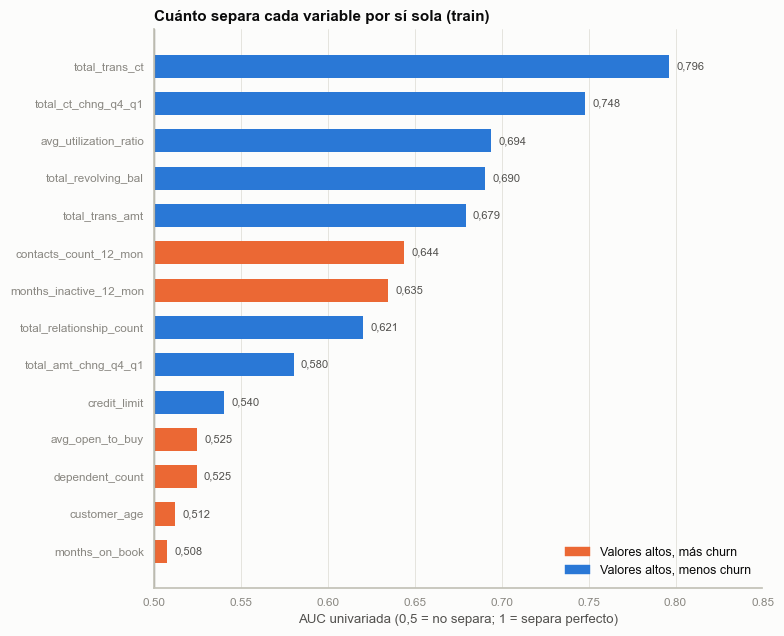

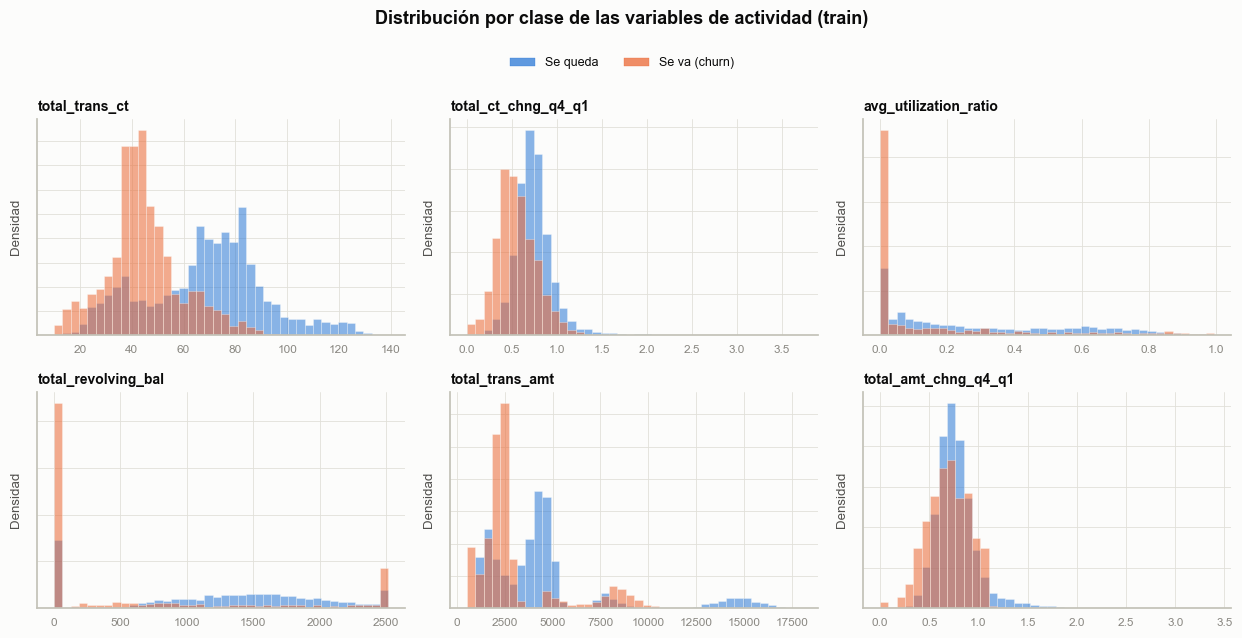

In [40]:
display(resumen_num[["auc_univariada", "sentido", "mediana_se_queda", "mediana_se_va"]].round(3))
fig = graficos.barras_auc_univariada(resumen_num, "Cuánto separa cada variable por sí sola (train)")
reportes.mostrar_figura(fig, "eda_01_auc_univariada");

variables_actividad = ["total_trans_ct", "total_ct_chng_q4_q1", "avg_utilization_ratio",
                       "total_revolving_bal", "total_trans_amt", "total_amt_chng_q4_q1"]
fig = graficos.densidades_por_clase(X_eda, y_eda, variables_actividad,
                                    "Distribución por clase de las variables de actividad (train)")
reportes.mostrar_figura(fig, "eda_02_densidades_actividad");

#### Lectura y decisión

- **La actividad concentra la señal:** `total_trans_ct` (0,796) y `total_ct_chng_q4_q1` (0,748) encabezan; el churner típico hace 43 transacciones al año frente a 71 de quien se queda. Edad, antigüedad, dependientes y cupo casi no separan (0,508 a 0,540).
- Quien se va se concentra en menos transacciones y en saldo rotativo y utilización cercanos a cero.

**Decisión.** No se elimina ninguna variable por su AUC univariado: qué usa cada modelo lo decide la validación cruzada (4.3).

### 2.4 Monto y número de transacciones

Son las dos variables más fuertes y están muy correlacionadas (2.2): se grafican juntas para ver si la frontera es lineal. Los tramos de monto son solo descriptivos.

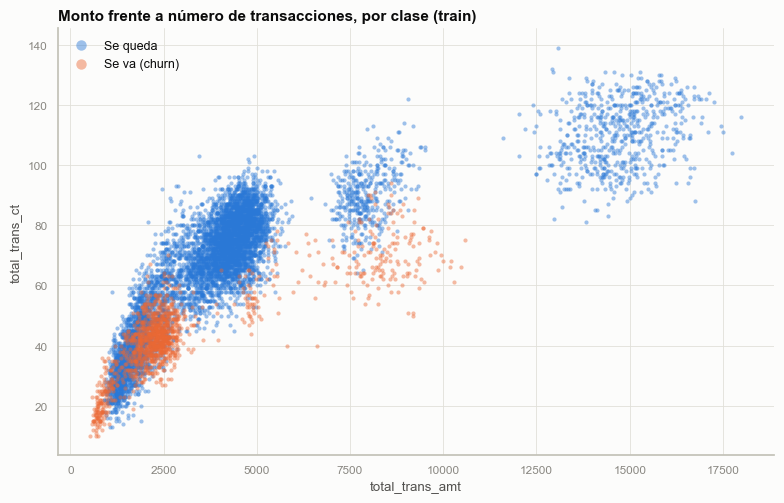

,clientes,churners,tasa_churn,ic95_inf,ic95_sup
tramo_monto,,,,,
hasta 3.000,3149,1041,0.3306,0.3144,0.3472
3.001 a 6.000,3802,88,0.0231,0.0188,0.0284
6.001 a 11.000,554,173,0.3123,0.2751,0.3520
más de 11.000,596,0,0.0000,0.0000,0.0064


AUC univariada del ticket promedio (monto / número de transacciones): 0.509


In [41]:
fig = graficos.dispersion_por_clase(X_eda, y_eda, "total_trans_amt", "total_trans_ct",
                                   "Monto frente a número de transacciones, por clase (train)")
reportes.mostrar_figura(fig, "eda_03_monto_vs_transacciones")

tramo_monto = exploracion.tramos(X_eda["total_trans_amt"], *exploracion.TRAMOS_MONTO)
display(exploracion.tasa_por_nivel(pd.DataFrame({"tramo_monto": tramo_monto}), y_eda, "tramo_monto").round(4))

ticket_promedio = X_eda["total_trans_amt"] / X_eda["total_trans_ct"]
auc_ticket = exploracion.resumen_numericas(pd.DataFrame({"ticket_promedio": ticket_promedio}), y_eda)
print(f"AUC univariada del ticket promedio (monto / número de transacciones): {auc_ticket.iloc[0]['auc_univariada']:.3f}")

#### Lectura y decisión

- **Riesgo no monótono por monto:** churn de 33,06 % hasta 3.000, 2,31 % de 3.001 a 6.000, 31,23 % de 6.001 a 11.000 y **0 % sobre 11.000** (0 de 596; IC 95 % de 0 % a 0,64 %).
- **A igual monto, quien se va transacciona menos** (mediana de 54 frente a 75, y de 69 frente a 90). El ticket promedio solo separa poco (AUC de 0,509).

**Decisión.** La frontera no es lineal: se comparan modelos no lineales con la logística y el ticket promedio entra como candidata (4.3).

### 2.5 Saldo rotativo: dos extremos de riesgo

El barrido mostró muchos ceros en el saldo rotativo (deuda que se arrastra en la tarjeta) y un pico en su máximo: se mide el churn en cero, en el máximo y en medio.

In [42]:
saldo_maximo = X_eda["total_revolving_bal"].max()
tramo_saldo = exploracion.tramos(
    X_eda["total_revolving_bal"], [-0.5, 0.5, saldo_maximo - 0.5, saldo_maximo + 0.5],
    ["0 (sin saldo)", f"1 a {saldo_maximo - 1:,}".replace(",", "."), f"{saldo_maximo:,} (máximo)".replace(",", ".")])
tabla_saldo = exploracion.tasa_por_nivel(pd.DataFrame({"tramo_saldo": tramo_saldo}), y_eda, "tramo_saldo")
tabla_saldo["pct_clientes"] = 100 * tabla_saldo["clientes"] / len(X_eda)
display(tabla_saldo.round(4))

,clientes,churners,tasa_churn,ic95_inf,ic95_sup,pct_clientes
tramo_saldo,,,,,,
0 (sin saldo),1968,719,0.3653,0.3444,0.3869,24.2933
1 a 2.516,5733,453,0.0790,0.0723,0.0863,70.7690
2.517 (máximo),400,130,0.3250,0.2810,0.3724,4.9377


#### Lectura y decisión

- **Riesgo en U:** 36,53 % de churn sin saldo (24,29 % de train), 32,50 % en el máximo (2.517; 4,94 %) y 7,90 % en medio. Hipótesis: perfiles distintos, el poco vinculado y el que migra deuda o tiene dificultades.
- Los clientes con exactamente 2.517 sugieren un **tope de registro** (limitación).

**Decisión.** Se prueban las candidatas `saldo_cero` y `saldo_en_maximo` (4.3); los árboles aprenden la U solos.

### 2.6 Relación con el banco

Productos, inactividad, contactos y dependientes: tasa de churn por valor, con **intervalo de confianza de 95 %** (Wilson) y tamaño de cada grupo.

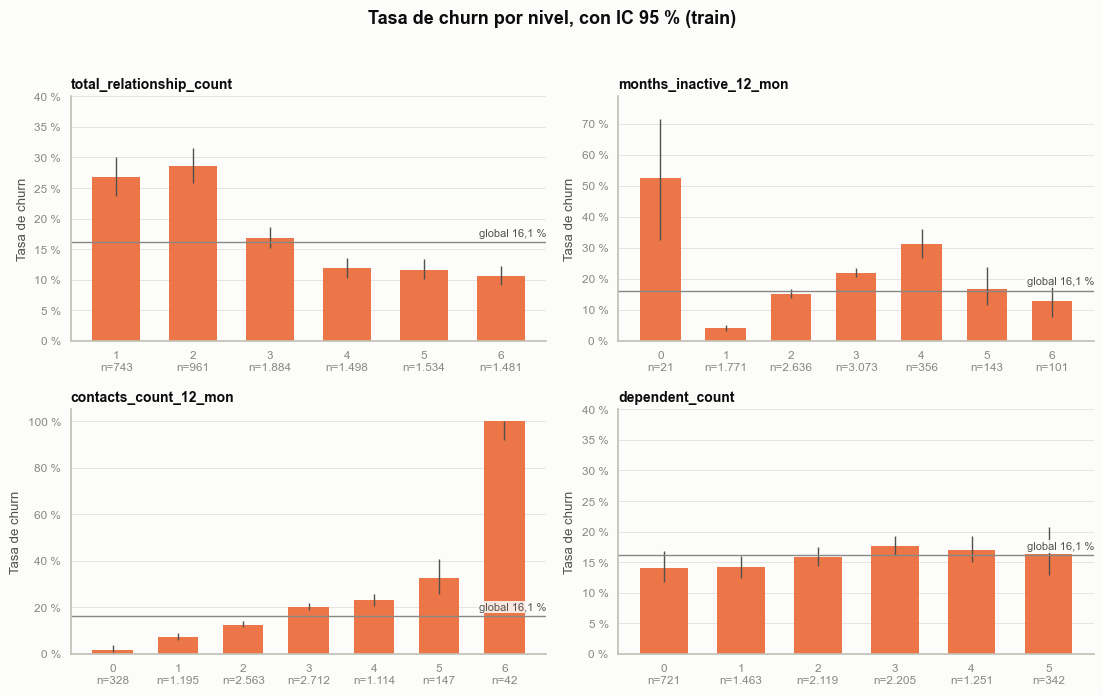

,clientes,churners,tasa_churn,ic95_inf,ic95_sup
total_relationship_count,,,,,
1,743,199,0.2678,0.2372,0.3008
2,961,275,0.2862,0.2585,0.3155
3,1884,317,0.1683,0.1520,0.1858
4,1498,177,0.1182,0.1028,0.1355
5,1534,178,0.1160,0.1010,0.1330
6,1481,156,0.1053,0.0907,0.1220


,clientes,churners,tasa_churn,ic95_inf,ic95_sup
contacts_count_12_mon,,,,,
0,328,5,0.0152,0.0065,0.0352
1,1195,85,0.0711,0.0579,0.0871
2,2563,321,0.1252,0.1130,0.1386
3,2712,546,0.2013,0.1867,0.2168
4,1114,255,0.2289,0.2052,0.2545
5,147,48,0.3265,0.2560,0.4059
6,42,42,1.0000,0.9162,1.0000


In [43]:
variables_relacion = ["total_relationship_count", "months_inactive_12_mon",
                      "contacts_count_12_mon", "dependent_count"]
tablas_relacion = {col: exploracion.tasa_por_nivel(X_eda, y_eda, col) for col in variables_relacion}
fig = graficos.tasas_por_nivel(tablas_relacion, tasa_global, "Tasa de churn por nivel, con IC 95 % (train)")
reportes.mostrar_figura(fig, "eda_04_tasas_relacion")
display(tablas_relacion["total_relationship_count"].round(4))
display(tablas_relacion["contacts_count_12_mon"].round(4))

#### Lectura y decisión

- **Más productos, menos churn** (26,78 % con uno frente a 10,53 % a 11,82 % con cuatro a seis); más meses inactivo y más contactos, más churn.
- **Los 42 clientes con 6 contactos se fueron todos** (IC 95 % de 91,62 % a 100 %).

**Decisión.** Se conservan como numéricas. Los 6 contactos sugieren una **posible fuga temporal** (contactos del propio retiro): se mide el modelo sin la variable en 5.7.

### 2.7 Variables demográficas y de producto

Tasa por categoría, chi cuadrado y **V de Cramér** (fuerza de la asociación, de 0 a 1; bajo 0,1 es débil).

,categorias,p_valor,v_cramer,categoria_menos_frecuente,clientes_categoria_menos_frecuente
variable,,,,,
gender,2,0.0002,0.0417,M,3829
income_category,6,0.0387,0.0381,$120K +,588
education_level,7,0.2039,0.0324,Doctorate,356
marital_status,4,0.1343,0.0262,Divorced,599
card_category,4,0.5165,0.0168,Platinum,17


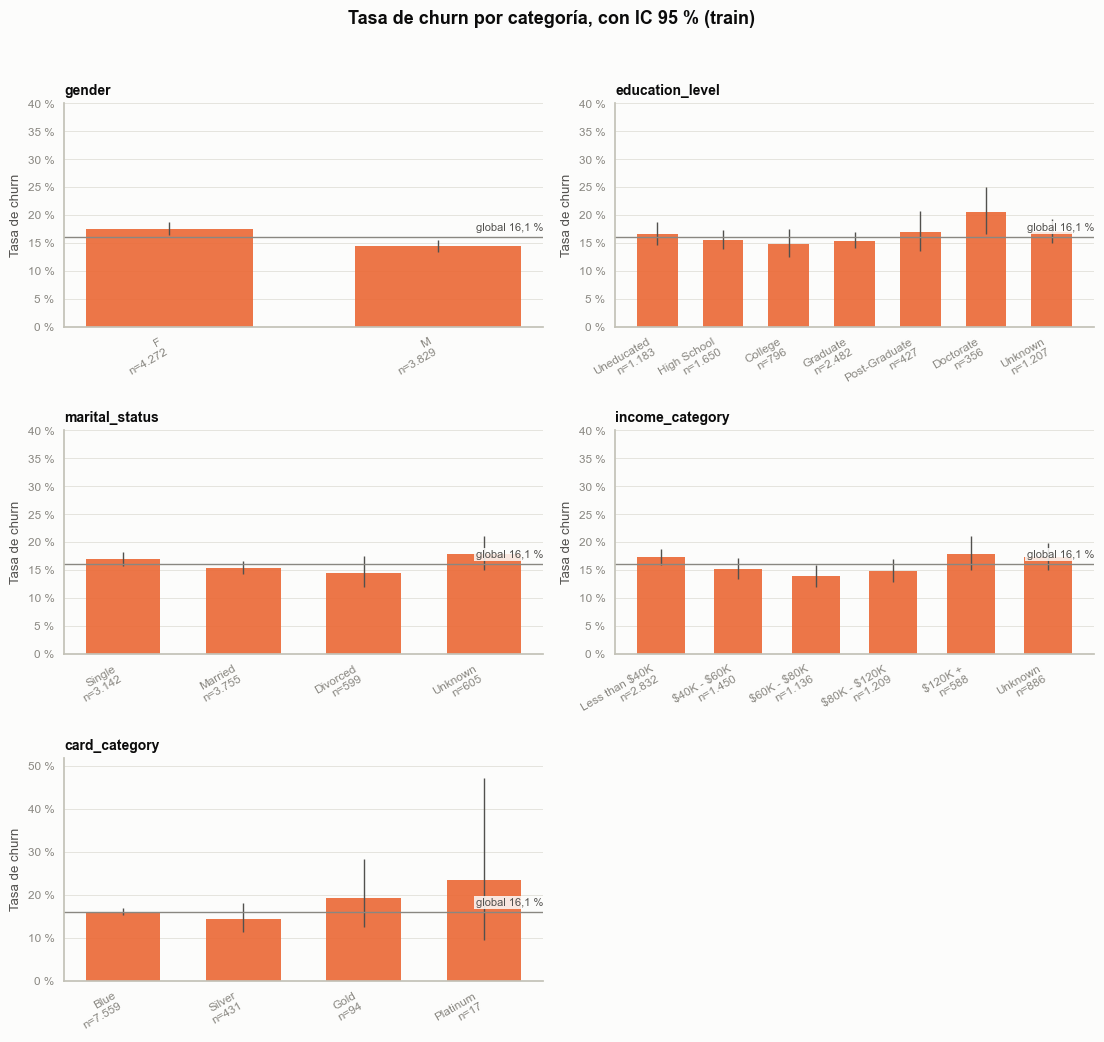

,clientes,churners,tasa_churn,ic95_inf,ic95_sup
card_category,,,,,
Blue,7559,1218,0.1611,0.1530,0.1696
Silver,431,62,0.1439,0.1139,0.1801
Gold,94,18,0.1915,0.1247,0.2825
Platinum,17,4,0.2353,0.0956,0.4726


Tasa de churn de la categoría Unknown:


,,clientes,churners,tasa_churn,ic95_inf,ic95_sup
,education_level,,,,,
education_level,Unknown,1207,205,0.1698,0.1497,0.1921
marital_status,Unknown,605,108,0.1785,0.1501,0.2110
income_category,Unknown,886,153,0.1727,0.1492,0.1990


In [44]:
asociacion = exploracion.asociacion_categoricas(X_eda, y_eda)
reportes.guardar_tabla(asociacion, "eda_asociacion_categoricas", decimales=4)
display(asociacion.round(4))

tablas_categoricas = {col: exploracion.tasa_por_nivel(X_eda, y_eda, col, orden)
                      for col, orden in datos.ORDEN_CATEGORIAS.items()}
fig = graficos.tasas_por_nivel(tablas_categoricas, tasa_global,
                               "Tasa de churn por categoría, con IC 95 % (train)", rotar=True)
reportes.mostrar_figura(fig, "eda_05_tasas_categoricas")
display(tablas_categoricas["card_category"].round(4))
print("Tasa de churn de la categoría Unknown:")
display(pd.concat({col: tabla.loc[["Unknown"]] for col, tabla in tablas_categoricas.items() if "Unknown" in tabla.index}).round(4))

#### Lectura y decisión

- **Asociación débil:** la V de Cramér mayor es la de `gender` (0,042). Solo `gender` (p = 0,0002) e `income_category` (p = 0,039) son significativas: mujeres 17,53 % de churn, hombres 14,44 %.
- Sin gradiente en educación ni ingresos; `Unknown` se parece a la tasa global; Gold (94) y Platinum (17) son muy pequeñas.

**Decisión.** One-Hot, `Unknown` como categoría propia y las de menos de 100 clientes agrupadas. La validación cruzada decide qué modelos las usan (4.3).

### 2.8 Anomalías que limitan la interpretación

Dos patrones que parecen efectos de la captura de datos y condicionan qué se puede concluir.

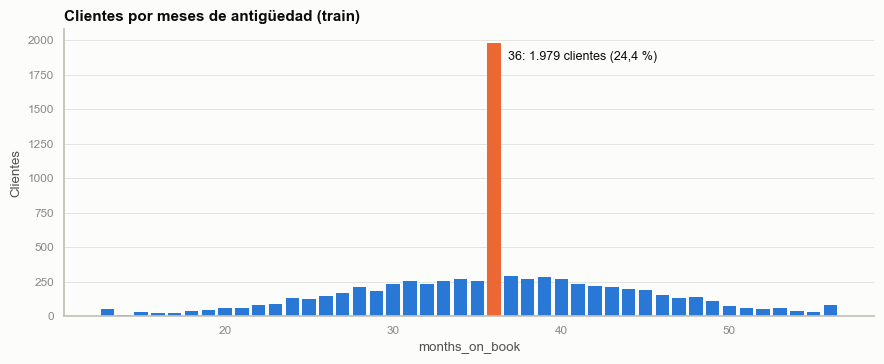

Clientes con 36 meses: 1979 (24.43 %)
Tasa de churn con 36 meses: 17.48% | resto: 15.62%


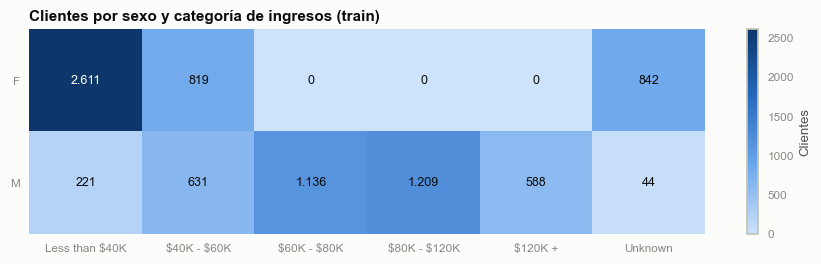

Mujeres en rangos de 60K o más: 0
Proporción de mujeres entre los ingresos Unknown: 95.03%


In [45]:
moda_antiguedad = exploracion.concentracion_moda(X_eda, "months_on_book")
fig = graficos.barras_conteo(X_eda, "months_on_book", moda_antiguedad["valor"],
                             "Clientes por meses de antigüedad (train)")
reportes.mostrar_figura(fig, "eda_06_antiguedad")
es_moda = X_eda["months_on_book"] == moda_antiguedad["valor"]
print(f"Clientes con {moda_antiguedad['valor']} meses: {moda_antiguedad['clientes']} ({moda_antiguedad['porcentaje']:.2f} %)")
print(f"Tasa de churn con {moda_antiguedad['valor']} meses: {y_eda[es_moda].mean():.2%} | resto: {y_eda[~es_moda].mean():.2%}")

sexo_ingresos = pd.crosstab(X_eda["gender"], X_eda["income_category"])[datos.ORDEN_CATEGORIAS["income_category"]]
fig = graficos.tabla_cruzada(sexo_ingresos, "Clientes por sexo y categoría de ingresos (train)")
reportes.mostrar_figura(fig, "eda_07_sexo_ingresos")
print(f"Mujeres en rangos de 60K o más: {sexo_ingresos.loc['F', ['$60K - $80K', '$80K - $120K', '$120K +']].sum()}")
print(f"Proporción de mujeres entre los ingresos Unknown: {sexo_ingresos.loc['F', 'Unknown'] / sexo_ingresos['Unknown'].sum():.2%}")

#### Lectura y decisión

- **Pico de 36 meses de antigüedad:** 1.979 clientes (24,43 %), muy por encima de los meses vecinos; probable relleno. Churn de 17,48 % frente a 15,62 % en el resto. Se conserva y se reporta como limitación.
- **Sexo e ingresos no son independientes:** ninguna mujer con 60K o más y 95,03 % de los `Unknown` son mujeres. No se sacan conclusiones por sexo ni por ingresos (5.7).

### 2.9 Resumen de decisiones del EDA

| # | Hallazgo (train) | Decisión | Se aplica en |
|---|---|---|---|
| 1 | 16,07 % de churn; baseline de 83,93 % | Elegir por AUC, no por accuracy | Fases 4 y 5 |
| 2 | La actividad concentra la señal | No eliminar variables por AUC univariado | 4.3 y 5.6 |
| 3 | Colas largas con atípicos reales | Yeo-Johnson y estandarización en el pipeline | Fase 3 |
| 4 | `avg_open_to_buy` es redundante | Eliminarla | Fase 3 |
| 5 | Monto no monótono e interacción con frecuencia | Modelos no lineales; ticket promedio candidato | 4.3 |
| 6 | Saldo rotativo en U | Candidatas `saldo_cero` y `saldo_en_maximo` | 4.3 |
| 7 | 6 contactos = 100 % de churn | Medir el modelo sin `contacts_count_12_mon` | 5.7 |
| 8 | Categóricas débiles | One-Hot; la validación cruzada decide si se usan | Fase 3 y 4.3 |
| 9 | Pico de 36 meses; sexo e ingresos no independientes | Conservar y reportar; sin conclusiones por sexo | 5.7 y 5.8 |

## CRISP-DM Fase 3: Preparación de los datos

### 3.1 Pipeline sin fuga

Las decisiones de 2.9 se vuelven código en `churn.features`. Todo paso que aprende de los datos va dentro de un `Pipeline`: en cada pliegue se ajusta solo con su parte de entrenamiento y el test nunca influye (**sin fuga de información**).

- `variables`: elimina `avg_open_to_buy` y puede crear `ticket_promedio`, `saldo_cero` y `saldo_en_maximo` (se deciden en 4.3).
- `codificador`: One-Hot de las 5 categóricas y, en los modelos sensibles a la escala (logística, SVM y red neuronal), Yeo-Johnson con estandarización. Árboles y ensambles no se escalan.

#### Las dos preparaciones, ajustadas con train

In [46]:
preparaciones = {
    "con escalado (logística, SVM, red neuronal)": features.construir_preparacion(
        escalar=True, ticket_promedio=True, indicadores_saldo=True),
    "sin escalado (árboles y ensambles)": features.construir_preparacion(
        escalar=False, ticket_promedio=True, indicadores_saldo=True),
}
for nombre, preparacion in preparaciones.items():
    preparacion.fit(particion.X_train)
    print(f"{nombre}: {len(features.nombres_salida(preparacion))} columnas de salida (candidatas activadas para mostrarlas)")

prep_escalada = preparaciones["con escalado (logística, SVM, red neuronal)"]
nombres_salida = features.nombres_salida(prep_escalada)
resumen_prep = features.resumen_preparacion(prep_escalada)
display(resumen_prep["columnas_por_origen"])
print(f"Categorías agrupadas como infrecuentes (menos de {features.MIN_FRECUENCIA_CATEGORIA} clientes en train): {resumen_prep['infrecuentes']}")
print(f"Saldo máximo aprendido de train para saldo_en_maximo: {resumen_prep['saldo_maximo']:,.0f}")

con escalado (logística, SVM, red neuronal): 37 columnas de salida (candidatas activadas para mostrarlas)
sin escalado (árboles y ensambles): 37 columnas de salida (candidatas activadas para mostrarlas)


,columnas
origen,
One-Hot,21
numérica original,13
candidata,3


Categorías agrupadas como infrecuentes (menos de 100 clientes en train): {'card_category': ['Gold', 'Platinum']}
Saldo máximo aprendido de train para saldo_en_maximo: 2,517


#### Lectura y decisión

- **37 columnas** con las candidatas activadas (34 sin ellas): 13 numéricas, 3 candidatas y 21 One-Hot.
- Solo `card_category` tiene categorías bajo 100 clientes (Gold y Platinum quedan juntas). El saldo máximo aprendido es **2.517**, el tope del EDA.

### 3.2 Controles

#### Chequeos: train ajusta, test solo transforma

In [47]:
for nombre, preparacion in preparaciones.items():
    print(f"Variante {nombre}:")
    display(features.verificar_preparacion(preparacion, particion.X_train, particion.X_test))

Variante con escalado (logística, SVM, red neuronal):


,chequeo,cumple,detalle
0,Sin faltantes ni infinitos en train,True,"8,101 x 37"
1,Sin faltantes ni infinitos en test,True,"2,026 x 37"
2,avg_open_to_buy no llega al modelo,True,37 columnas de salida
3,Nombres de columna únicos,True,
4,Train estandarizado (media 0),True,máx |media| = 3.9e-15
5,Train estandarizado (desviación 1),True,máx |desv - 1| = 2.2e-16
6,Test transformado con parámetros de train,True,máx |media test| = 0.047 (distinto de 0)


Variante sin escalado (árboles y ensambles):


,chequeo,cumple,detalle
0,Sin faltantes ni infinitos en train,True,"8,101 x 37"
1,Sin faltantes ni infinitos en test,True,"2,026 x 37"
2,avg_open_to_buy no llega al modelo,True,37 columnas de salida
3,Nombres de columna únicos,True,


#### Efecto de Yeo-Johnson sobre la asimetría

In [48]:
antes = prep_escalada.named_steps["variables"].transform(particion.X_train)
despues = pd.DataFrame(prep_escalada.transform(particion.X_train), columns=nombres_salida, index=particion.X_train.index)
variables_cola_larga = ["total_ct_chng_q4_q1", "total_trans_amt", "total_amt_chng_q4_q1", "credit_limit", features.COLUMNA_TICKET]
efecto = pd.DataFrame({"asimetria_antes": antes[variables_cola_larga].skew(),
                       "asimetria_despues": despues[variables_cola_larga].skew()})
display(efecto.round(2))

,asimetria_antes,asimetria_despues
total_ct_chng_q4_q1,2.25,-0.08
total_trans_amt,2.05,0.00
total_amt_chng_q4_q1,1.80,-0.09
credit_limit,1.68,0.10
ticket_promedio,1.90,-0.01


#### Lectura y decisión

- **Sin fuga:** sin faltantes ni infinitos. Train queda con media 0 y desviación 1 y el test no (hasta 0,047): el test se transforma con parámetros de train.
- **Yeo-Johnson corrige las colas:** la asimetría de las cinco variables pasa de 1,68 a 2,25 a quedar entre -0,09 y 0,10.

**Decisión.** Los pasos entran al pipeline de cada modelo. `tests/test_features.py` verifica que el test no cambia lo aprendido.

## CRISP-DM Fase 4: Modelado

**PyCaret explora (4.1) y el modelado manual selecciona (4.2 a 4.7).** Protocolo del modelado manual:

- Validación cruzada estratificada de 5 pliegues sobre train, iguales para todos.
- **AUC** para elegir; AP y la brecha entre train y validación como apoyo.
- El desbalance (ninguno, pesos o SMOTE) se trata como un hiperparámetro más.
- Dentro de cada modelo gana el mayor AUC; los candidatos a menos de una desviación empatan y se prefiere la estrategia más simple.

Cada búsqueda se guarda en `models/experimentos/` con una **huella digital** (datos, grilla, variables y versiones): si nada cambió, se carga en lugar de repetirse.

### 4.1 PyCaret: exploración de familias

PyCaret entrena unos quince algoritmos con valores por defecto. Sirve para ver qué familias funcionan y comprobar que el catálogo manual no deja fuera una competitiva. **No elige el modelo ni influye en las variables ni en los hiperparámetros.**

In [49]:
tabla_pycaret = comparacion.referencia_pycaret(particion.X_train, particion.y_train)
reportes.guardar_tabla(tabla_pycaret, "modelado_pycaret", decimales=None)
display(tabla_pycaret)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.9702,0.9931,0.8722,0.9384,0.9040,0.8864,0.8873,0.320
xgboost,Extreme Gradient Boosting,0.9691,0.9922,0.8684,0.9351,0.9004,0.8822,0.8831,0.202
gbc,Gradient Boosting Classifier,0.9630,0.9892,0.8271,0.9356,0.8776,0.8559,0.8584,0.608
rf,Random Forest Classifier,0.9475,0.9847,0.7377,0.9199,0.8182,0.7880,0.7950,0.266
ada,Ada Boost Classifier,0.9554,0.9829,0.8377,0.8797,0.8578,0.8314,0.8320,0.250
et,Extra Trees Classifier,0.9242,0.9712,0.5764,0.9222,0.7084,0.6677,0.6926,0.238
lr,Logistic Regression,0.9133,0.9375,0.6369,0.7832,0.7015,0.6515,0.6569,2.324
ridge,Ridge Classifier,0.9100,0.9351,0.5274,0.8578,0.6519,0.6038,0.6280,0.118
lda,Linear Discriminant Analysis,0.9145,0.9351,0.6542,0.7793,0.7101,0.6605,0.6647,0.116
svm,SVM - Linear Kernel,0.9005,0.9190,0.5946,0.7358,0.6551,0.5980,0.6041,0.128


#### Lectura y decisión

- **Boosting encabeza** (LightGBM, XGBoost y Gradient Boosting), seguido de Random Forest y AdaBoost; los lineales quedan lejos (logística, 0,9375).
- **Nada fuera del temario compite:** el mejor no visto en clase es Extra Trees (0,9712), y KNN queda entre los peores (0,7877), por lo que no se incluye. El `dummy` da AUC de 0,5000.
- Sus cifras no se comparan con las manuales: PyCaret valida sobre el 80 % de train, con otros pliegues y su propia preparación.

**Decisión.** El catálogo manual cubre las familias que funcionan. La selección la hace la validación cruzada (4.3 a 4.7).

### 4.2 Catálogo de modelos

Los **diez métodos de clasificación vistos en el curso**, cada uno por una razón:

| Modelo | Por qué se incluye | Qué se prueba |
|---|---|---|
| Regresión logística | Referencia lineal e interpretable | `C` y penalización L1 o L2 |
| SVM | Margen máximo con el truco del kernel | Kernels lineal, polinomial, RBF y sigmoidal; `C` (margen suave) y `gamma` |
| Red neuronal | Relaciones no lineales aprendidas por propagación hacia atrás | Activación ReLU, tanh y sigmoidal; tamaño de las capas; `alpha` (L2) |
| Árbol de decisión | Base de los ensambles y el más fácil de explicar | Profundidad y mínimo de clientes por hoja |
| Bagging de árboles | Reduce la varianza promediando árboles | Fracción de clientes y de variables por árbol |
| Random Forest | Bagging que además sortea variables en cada corte | Profundidad, mínimo por hoja y variables por corte |
| AdaBoost | Boosting que da más peso a los mal clasificados | Profundidad del árbol base, número de árboles y tasa de aprendizaje |
| Gradient Boosting | Boosting en que cada árbol ajusta el error que queda | Número de árboles, tasa de aprendizaje y profundidad |
| XGBoost | Gradient boosting con regularización | Número de árboles, tasa de aprendizaje y profundidad |
| LightGBM | Boosting que crece por hojas; mejor familia en 4.1 | Número de árboles, tasa de aprendizaje y número de hojas |

**No incluidos:** la regresión lineal y polinomial predicen un número, no una clase; las redes con Keras exigirían otra librería y la red de scikit-learn cubre la misma arquitectura. Votación y *stacking* combinan modelos: se prueban en 4.7.

In [50]:
REENTRENAR = False  # True: ignora la caché y repite todas las búsquedas
catalogo = modelos.catalogo_modelos()
display(comparacion.tabla_catalogo(catalogo))

,familia,preparacion,estrategias_desbalance,hiperparametros,candidatos,ajustes_cv
modelo,,,,,,
Regresión logística,lineal,con escalado,"ninguna, pesos, SMOTE","C, penalty",30,150
SVM,kernel,con escalado,"ninguna, pesos, SMOTE","kernel, C, gamma",72,360
Red neuronal (MLP),red neuronal,con escalado,"ninguna, SMOTE","activation, hidden_layer_sizes, alpha",72,360
Árbol de decisión,árbol,sin escalado,"ninguna, pesos, SMOTE","max_depth, min_samples_leaf",36,180
Bagging de árboles,bagging,sin escalado,"ninguna, SMOTE","max_samples, max_features",8,40
Random Forest,bagging,sin escalado,"ninguna, pesos, SMOTE","max_depth, min_samples_leaf, max_features",24,120
AdaBoost,boosting,sin escalado,"ninguna, SMOTE","estimator__max_depth, n_estimators, learning_rate",24,120
Gradient Boosting,boosting,sin escalado,"ninguna, SMOTE","n_estimators, learning_rate, max_depth",16,80
XGBoost,boosting,sin escalado,"ninguna, pesos, SMOTE","n_estimators, learning_rate, max_depth",24,120


### 4.3 Selección de variables

**Regla única, modelo por modelo:** una variable se queda solo si su aporte medio de AUC es positivo, mayor que su desviación y aparece en al menos 4 de 5 pliegues. Si no, se retira (parsimonia).

#### ¿Aportan las cinco categóricas?

In [51]:
tabla_categoricas = comparacion.experimento_categoricas(catalogo, particion.X_train, particion.y_train)
reportes.guardar_tabla(tabla_categoricas, "modelado_categoricas")
display(tabla_categoricas.round(4))

decision_categoricas = comparacion.aplicar_decision_categoricas(catalogo, tabla_categoricas)
print(f"Modelos que conservan las categóricas: {list(decision_categoricas[decision_categoricas].index) or 'ninguno'}")
assert decision_categoricas["LightGBM"] == produccion.USA_CATEGORICAS_OFICIAL, "produccion.py no coincide con esta decisión"

,auc_con_categoricas,auc_sin_categoricas,aporte_medio,aporte_desv,pliegues_en_que_aportan,aporte_claro
modelo,,,,,,
Regresión logística,0.9377,0.9365,0.0012,0.0012,5,True
SVM,0.9673,0.9705,-0.0031,0.0018,0,False
Red neuronal (MLP),0.9635,0.9597,0.0038,0.0157,2,False
Árbol de decisión,0.8761,0.8860,-0.0099,0.0130,2,False
Bagging de árboles,0.9850,0.9861,-0.0011,0.0014,2,False
Random Forest,0.9871,0.9897,-0.0026,0.0015,0,False
AdaBoost,0.9740,0.9742,-0.0002,0.0004,0,False
Gradient Boosting,0.9901,0.9899,0.0002,0.0004,3,False
XGBoost,0.9922,0.9928,-0.0006,0.0009,1,False


Modelos que conservan las categóricas: ['Regresión logística']


#### ¿Aportan las tres variables candidatas?

`ticket_promedio`, `saldo_cero` y `saldo_en_maximo`, en sus cuatro combinaciones, contra la versión base de cada modelo.

In [52]:
tabla_candidatas = comparacion.experimento_candidatas(catalogo, particion.X_train, particion.y_train)
reportes.guardar_tabla(tabla_candidatas, "modelado_candidatas", indice=False)
mejora, pliegues = comparacion.tablas_candidatas(tabla_candidatas, catalogo)
print("Mejora media de AUC contra la versión base:")
display(mejora.round(4))
print("Pliegues (de 5) en que mejora:")
display(pliegues)

decision_candidatas = comparacion.decidir_candidatas(tabla_candidatas)
display(comparacion.aplicar_decision_candidatas(catalogo, decision_candidatas))

Mejora media de AUC contra la versión base:


combinacion,base,+ ticket,+ saldo,+ ticket + saldo
modelo,,,,
Regresión logística,0.0,0.0050,0.0091,0.0130
SVM,0.0,0.0037,0.0009,0.0040
Red neuronal (MLP),0.0,0.0050,0.0035,0.0086
Árbol de decisión,0.0,0.0022,-0.0005,0.0043
Bagging de árboles,0.0,0.0007,-0.0006,0.0004
Random Forest,0.0,0.0010,-0.0003,0.0004
AdaBoost,0.0,0.0004,0.0000,0.0004
Gradient Boosting,0.0,-0.0003,-0.0001,-0.0004
XGBoost,0.0,-0.0007,-0.0004,-0.0002


Pliegues (de 5) en que mejora:


combinacion,base,+ ticket,+ saldo,+ ticket + saldo
modelo,,,,
Regresión logística,0,5,5,5
SVM,0,5,4,5
Red neuronal (MLP),0,2,3,2
Árbol de decisión,0,3,2,4
Bagging de árboles,0,4,2,2
Random Forest,0,5,2,3
AdaBoost,0,4,0,4
Gradient Boosting,0,1,3,1
XGBoost,0,2,2,2


,ticket_promedio,indicadores_saldo
Regresión logística,True,True
SVM,True,True
Red neuronal (MLP),False,False
Árbol de decisión,False,False
Bagging de árboles,False,False
Random Forest,True,False
AdaBoost,False,False
Gradient Boosting,False,False
XGBoost,False,False
LightGBM,False,False


#### Lectura y decisión

- **Categóricas:** solo la logística cumple la regla, y por poco (+0,0012, en 5 de 5 pliegues). En SVM, Random Forest y AdaBoost bajan el AUC en los 5 pliegues.
- **Candidatas:** ayudan a los modelos que no hacen cortes propios. La logística gana +0,0130 y SVM +0,0040 con las tres, en 5 de 5 pliegues; Random Forest gana +0,0010 con el ticket promedio. En los demás la mejora no es consistente.

**Decisión.** Solo la logística conserva las categóricas. Logística y SVM usan las tres candidatas, Random Forest el ticket promedio y el resto la versión base. Los modelos de boosting usan 13 de las 21 columnas del archivo.

### 4.4 Ronda 1: búsqueda de hiperparámetros

`GridSearchCV` recorre la grilla de cada modelo con las tres estrategias de desbalance.

In [53]:
ronda_1 = comparacion.entrenar_o_cargar(catalogo, particion.X_train, particion.y_train,
                                        config.RUTA_EXPERIMENTOS, "ronda_1", reentrenar=REENTRENAR)
columnas_tabla = ["familia", "auc_cv", "auc_cv_desv", "ap_cv", "auc_train", "brecha_train_cv",
                  "tiempo_ajuste_s", "candidatos", "estrategia", "mejores_hiperparametros"]
display(ronda_1.tabla_cv()[columnas_tabla].round(4))

print("Mejor AUC de CV por kernel de SVM y por activación de la red neuronal:")
display(comparacion.auc_por_valor(ronda_1.modelos["SVM"], "kernel").round(4))
display(comparacion.auc_por_valor(ronda_1.modelos["Red neuronal (MLP)"], "activation").round(4))

print("Mejor AUC de CV por estrategia de desbalance:")
tabla_estrategias = comparacion.auc_por_estrategia(ronda_1)
reportes.guardar_tabla(tabla_estrategias, "modelado_estrategias")
display(tabla_estrategias.round(4))

   1/10 Regresión logística: cargado de la caché (misma huella)
   2/10 SVM: cargado de la caché (misma huella)
   3/10 Red neuronal (MLP): cargado de la caché (misma huella)
   4/10 Árbol de decisión: cargado de la caché (misma huella)
   5/10 Bagging de árboles: cargado de la caché (misma huella)
   6/10 Random Forest: cargado de la caché (misma huella)
   7/10 AdaBoost: cargado de la caché (misma huella)
   8/10 Gradient Boosting: cargado de la caché (misma huella)
   9/10 XGBoost: cargado de la caché (misma huella)
   10/10 LightGBM: cargado de la caché (misma huella)


,familia,auc_cv,auc_cv_desv,ap_cv,auc_train,brecha_train_cv,tiempo_ajuste_s,candidatos,estrategia,mejores_hiperparametros
modelo,,,,,,,,,,
LightGBM,boosting,0.9940,0.0012,0.9721,1.0000,0.0060,0.3180,24,ninguna,"{'learning_rate': 0.03, 'n_estimators': 600, 'num_leaves': 15}"
XGBoost,boosting,0.9937,0.0015,0.9715,1.0000,0.0063,0.2565,24,ninguna,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 600}"
Gradient Boosting,boosting,0.9929,0.0020,0.9686,0.9999,0.0070,4.0549,16,ninguna,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}"
AdaBoost,boosting,0.9922,0.0020,0.9655,0.9996,0.0074,5.2123,24,ninguna,"{'estimator__max_depth': 2, 'learning_rate': 1.0, 'n_estimators': 600}"
Random Forest,bagging,0.9907,0.0023,0.9570,1.0000,0.0093,2.3197,24,ninguna,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}"
Bagging de árboles,bagging,0.9905,0.0023,0.9568,1.0000,0.0095,2.5486,8,ninguna,"{'max_features': 0.5, 'max_samples': 1.0}"
Red neuronal (MLP),red neuronal,0.9878,0.0018,0.9483,0.9978,0.0100,1.4824,72,SMOTE,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_layer_sizes': (64, 32)}"
SVM,kernel,0.9781,0.0048,0.9150,0.9967,0.0187,0.2367,72,ninguna,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}"
Árbol de decisión,árbol,0.9617,0.0051,0.8581,0.9842,0.0225,0.0288,36,ninguna,"{'max_depth': 8, 'min_samples_leaf': 20}"


Mejor AUC de CV por kernel de SVM y por activación de la red neuronal:


,auc_cv,auc_cv_desv,estrategia
kernel,,,
rbf,0.9781,0.0048,ninguna
poly,0.9534,0.0050,pesos
linear,0.9504,0.0025,pesos
sigmoid,0.8795,0.0093,ninguna


,auc_cv,auc_cv_desv,estrategia
activation,,,
tanh,0.9878,0.0018,SMOTE
relu,0.9798,0.0045,SMOTE
logistic,0.9723,0.0161,SMOTE


Mejor AUC de CV por estrategia de desbalance:


estrategia,ninguna,pesos,SMOTE,rango_entre_estrategias,desv_mejor_candidato
Regresión logística,0.9510,0.9510,0.9505,0.0006,0.0018
SVM,0.9781,0.9764,0.9768,0.0017,0.0048
Red neuronal (MLP),0.9755,NaN,0.9878,0.0123,0.0018
Árbol de decisión,0.9617,0.9530,0.9624,0.0094,0.0051
Bagging de árboles,0.9905,NaN,0.9907,0.0002,0.0023
Random Forest,0.9907,0.9912,0.9901,0.0011,0.0023
AdaBoost,0.9922,NaN,0.9924,0.0002,0.0020
Gradient Boosting,0.9929,NaN,0.9937,0.0008,0.0020
XGBoost,0.9937,0.9936,0.9936,0.0001,0.0015
LightGBM,0.9940,0.9938,0.9942,0.0004,0.0012


#### Lectura y decisión

- **LightGBM encabeza** (0,9940) y la logística cierra (0,9510).
- **Kernel de SVM:** el RBF (0,9781) supera al polinomial (0,9534), al lineal (0,9504) y al sigmoidal (0,8795): la frontera no es lineal, como anticipó el EDA (2.4 y 2.5).
- **Activación de la red:** tanh (0,9878) supera a ReLU (0,9798) y a la sigmoidal (0,9723).
- **Un árbol solo rinde 0,9617; 200 árboles en bagging, 0,9905:** es la reducción de varianza de los ensambles.
- **El desbalance casi no cambia el AUC,** salvo en la red neuronal (mejor con SMOTE) y el árbol (peor con pesos). Se trata al elegir cuántos contactar (5.4).

### 4.5 Óptimos en el borde de la grilla

Mejor AUC con cada valor del hiperparámetro principal y lista de los que quedaron en un **extremo de la grilla**, donde el mejor valor podría estar fuera de lo probado.

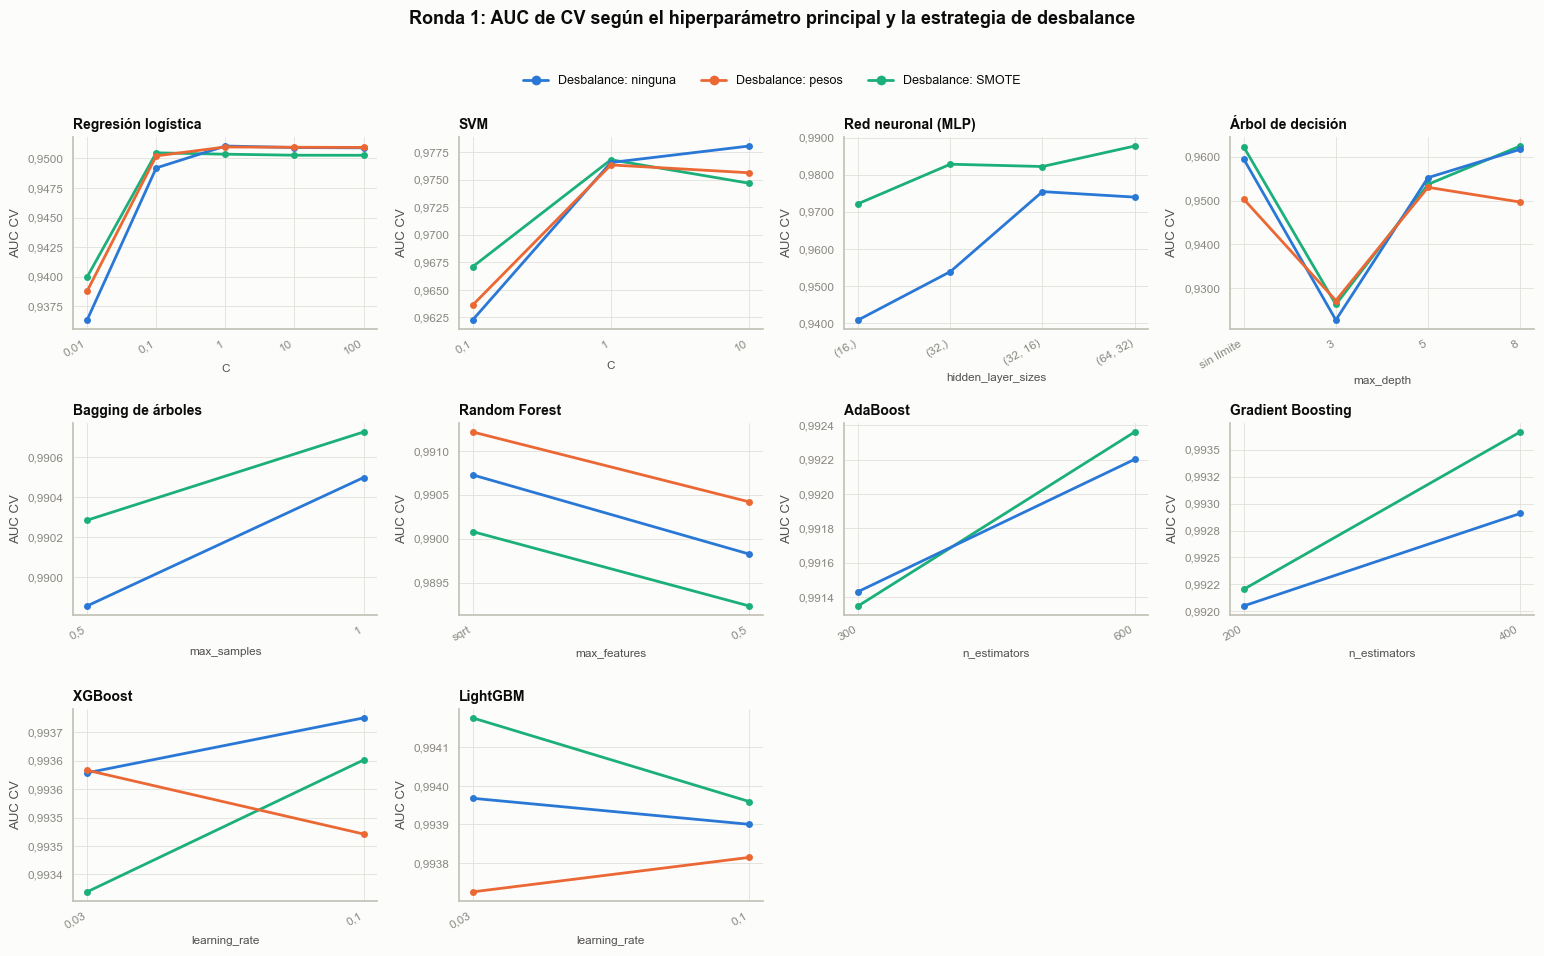

Hiperparámetros con el óptimo en un extremo de la grilla (ronda 1):


,modelo,hiperparametro,elegido,probados,extremo
0,SVM,C,10,"[0.1, 1, 10]",máximo
1,Red neuronal (MLP),hidden_layer_sizes,"(64, 32)","[(16,), (32,), (32, 16), (64, 32)]",máximo
2,Red neuronal (MLP),alpha,0.01,"[0.0001, 0.001, 0.01]",máximo
3,Árbol de decisión,min_samples_leaf,20,"[1, 5, 20]",máximo
4,Bagging de árboles,max_samples,1.0,"[0.5, 1.0]",máximo
5,Bagging de árboles,max_features,0.5,"[0.5, 1.0]",mínimo
6,Random Forest,min_samples_leaf,1,"[1, 5]",mínimo
7,AdaBoost,estimator__max_depth,2,"[1, 2]",máximo
8,AdaBoost,n_estimators,600,"[300, 600]",máximo
9,AdaBoost,learning_rate,1.0,"[0.1, 0.5, 1.0]",máximo


In [54]:
parametro_principal = {
    "Regresión logística": "C", "SVM": "C", "Red neuronal (MLP)": "hidden_layer_sizes",
    "Árbol de decisión": "max_depth", "Bagging de árboles": "max_samples",
    "Random Forest": "max_features", "AdaBoost": "n_estimators", "Gradient Boosting": "n_estimators",
    "XGBoost": "learning_rate", "LightGBM": "learning_rate",
}
paneles = {nombre: (ronda_1.modelos[nombre].resultados(), parametro) for nombre, parametro in parametro_principal.items()}
fig = graficos_modelado.efecto_hiperparametros(
    paneles, "Ronda 1: AUC de CV según el hiperparámetro principal y la estrategia de desbalance")
reportes.mostrar_figura(fig, "modelado_01_efecto_hiperparametros")

print("Hiperparámetros con el óptimo en un extremo de la grilla (ronda 1):")
bordes_ronda_1 = ronda_1.hiperparametros_en_borde()
reportes.guardar_tabla(bordes_ronda_1, "modelado_bordes_ronda_1", decimales=None, indice=False)
display(bordes_ronda_1)

#### Lectura y decisión

- Cada panel tiene su propio eje, muy estrecho en boosting.
- **19 hiperparámetros quedaron en un extremo,** en nueve de los diez modelos.

**Decisión.** Se amplían esas nueve grillas (ronda 2), conservando el kernel RBF y la activación tanh. La logística no, porque su óptimo quedó en el interior.

### 4.6 Ronda 2: ampliación de las grillas

Cada grilla ampliada contiene el óptimo anterior y lo extiende hacia el borde (`GRILLAS_RONDA_2`), con la estrategia "ninguna". **Regla de parada:** se seguiría ampliando solo si un modelo mantiene un borde **y** mejoró por más de una desviación. Es una regla práctica, no una prueba estadística.

In [55]:
ronda_2 = comparacion.entrenar_o_cargar(comparacion.ampliar_grillas(ronda_1, comparacion.GRILLAS_RONDA_2),
                                        particion.X_train, particion.y_train,
                                        config.RUTA_EXPERIMENTOS, "ronda_2", reentrenar=REENTRENAR)
rondas_1_2 = comparacion.comparar_rondas(ronda_1, ronda_2)
reportes.guardar_tabla(rondas_1_2, "modelado_rondas_1_2")
display(rondas_1_2.round(4))
a_ampliar = comparacion.modelos_a_ampliar(ronda_1, ronda_2)
print(f"Modelos que cumplen la regla para una ronda 3: {a_ampliar or 'ninguno'}")
assert set(a_ampliar) == set(comparacion.GRILLAS_RONDA_3), "Las grillas de ronda 3 no coinciden con la regla"

comparador = comparacion.combinar(ronda_1, ronda_2)
print("Bordes que se declaran en la versión final de cada modelo:")
bordes_finales = comparador.hiperparametros_en_borde()
reportes.guardar_tabla(bordes_finales, "modelado_bordes_final", decimales=None, indice=False)
display(bordes_finales)

   1/9 SVM: cargado de la caché (misma huella)
   2/9 Red neuronal (MLP): cargado de la caché (misma huella)
   3/9 Árbol de decisión: cargado de la caché (misma huella)
   4/9 Bagging de árboles: cargado de la caché (misma huella)
   5/9 Random Forest: cargado de la caché (misma huella)
   6/9 AdaBoost: cargado de la caché (misma huella)
   7/9 Gradient Boosting: cargado de la caché (misma huella)
   8/9 XGBoost: cargado de la caché (misma huella)
   9/9 LightGBM: cargado de la caché (misma huella)


,auc_cv_anterior,auc_cv_nueva,cambio,desv_nueva,hiperparametros_anterior,hiperparametros_nueva
modelo,,,,,,
SVM,0.9781,0.9788,0.0007,0.0049,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}","{'C': 3, 'gamma': 0.1, 'kernel': 'rbf'}"
Red neuronal (MLP),0.9878,0.9913,0.0035,0.0023,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_layer_sizes': (64, 32)}","{'activation': 'tanh', 'alpha': 0.1, 'hidden_layer_sizes': (128, 64, 32)}"
Árbol de decisión,0.9617,0.9622,0.0005,0.0057,"{'max_depth': 8, 'min_samples_leaf': 20}","{'max_depth': 10, 'min_samples_leaf': 20}"
Bagging de árboles,0.9905,0.9909,0.0004,0.0022,"{'max_features': 0.5, 'max_samples': 1.0}","{'max_features': 0.7, 'max_samples': 1.0}"
Random Forest,0.9907,0.9905,-0.0002,0.0021,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}","{'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 1}"
AdaBoost,0.9922,0.9928,0.0006,0.0012,"{'estimator__max_depth': 2, 'learning_rate': 1.0, 'n_estimators': 600}","{'estimator__max_depth': 3, 'learning_rate': 1.0, 'n_estimators': 1000}"
Gradient Boosting,0.9929,0.9936,0.0007,0.0016,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}","{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400}"
XGBoost,0.9937,0.9936,-0.0001,0.0016,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 600}","{'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600}"
LightGBM,0.9940,0.9941,0.0001,0.0009,"{'learning_rate': 0.03, 'n_estimators': 600, 'num_leaves': 15}","{'learning_rate': 0.03, 'n_estimators': 1000, 'num_leaves': 31}"


Modelos que cumplen la regla para una ronda 3: ninguno
Bordes que se declaran en la versión final de cada modelo:


,modelo,hiperparametro,elegido,probados,extremo
0,SVM,C,3.0,"[3, 10, 30]",mínimo
1,Árbol de decisión,min_samples_leaf,20.0,"[20, 40, 80]",mínimo
2,Bagging de árboles,max_features,0.7,"[0.3, 0.5, 0.7]",máximo
3,Random Forest,min_samples_leaf,1.0,"[1, 2]",mínimo
4,Random Forest,max_features,0.3,"[0.3, 0.5, 0.7]",mínimo
5,AdaBoost,estimator__max_depth,3.0,"[2, 3]",máximo
6,AdaBoost,n_estimators,1000.0,"[600, 1000]",máximo
7,Gradient Boosting,n_estimators,400.0,"[400, 800]",mínimo
8,Gradient Boosting,learning_rate,0.1,"[0.1, 0.2]",mínimo
9,Gradient Boosting,max_depth,4.0,"[3, 4]",máximo


#### Lectura y decisión

- Los cambios van de -0,0002 a +0,0035. Solo la red neuronal mejora más de una desviación (de 0,9878 a 0,9913, con capas más grandes y más regularización) y su óptimo quedó en el interior de la grilla ampliada.
- **Ningún modelo cumple la regla para seguir.** Quedan 13 bordes declarados, la mayoría en boosting, donde el AUC está en una meseta.

**Decisión.** Se detiene la búsqueda: seguir costaría cómputo sin cambiar el orden de los modelos.

### 4.7 Comparación final y finalistas

La **comparación pareada** contra el mejor, pliegue a pliegue, separa diferencias reales de ruido. Son **finalistas** los modelos a menos de una desviación del mejor: un criterio holgado de empate, no una prueba formal.

,familia,auc_cv,auc_cv_desv,ap_cv,auc_train,brecha_train_cv,tiempo_ajuste_s,candidatos,estrategia,mejores_hiperparametros
modelo,,,,,,,,,,
LightGBM,boosting,0.9941,0.0009,0.9733,1.0000,0.0059,0.9298,18,ninguna,"{'learning_rate': 0.03, 'n_estimators': 1000, 'num_leaves': 31}"
Gradient Boosting,boosting,0.9936,0.0016,0.9715,1.0000,0.0064,5.5285,8,ninguna,"{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400}"
XGBoost,boosting,0.9936,0.0016,0.9701,0.9999,0.0064,0.4640,18,ninguna,"{'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600}"
AdaBoost,boosting,0.9928,0.0012,0.9682,1.0000,0.0072,12.1006,12,ninguna,"{'estimator__max_depth': 3, 'learning_rate': 1.0, 'n_estimators': 1000}"
Red neuronal (MLP),red neuronal,0.9913,0.0023,0.9596,0.9960,0.0047,1.5402,16,ninguna,"{'activation': 'tanh', 'alpha': 0.1, 'hidden_layer_sizes': (128, 64, 32)}"
Bagging de árboles,bagging,0.9909,0.0022,0.9562,1.0000,0.0091,3.4776,3,ninguna,"{'max_features': 0.7, 'max_samples': 1.0}"
Random Forest,bagging,0.9905,0.0021,0.9566,1.0000,0.0095,2.8927,18,ninguna,"{'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 1}"
SVM,kernel,0.9788,0.0049,0.9160,0.9966,0.0178,0.2320,9,ninguna,"{'C': 3, 'gamma': 0.1, 'kernel': 'rbf'}"
Árbol de decisión,árbol,0.9622,0.0057,0.8602,0.9859,0.0237,0.0335,12,ninguna,"{'max_depth': 10, 'min_samples_leaf': 20}"


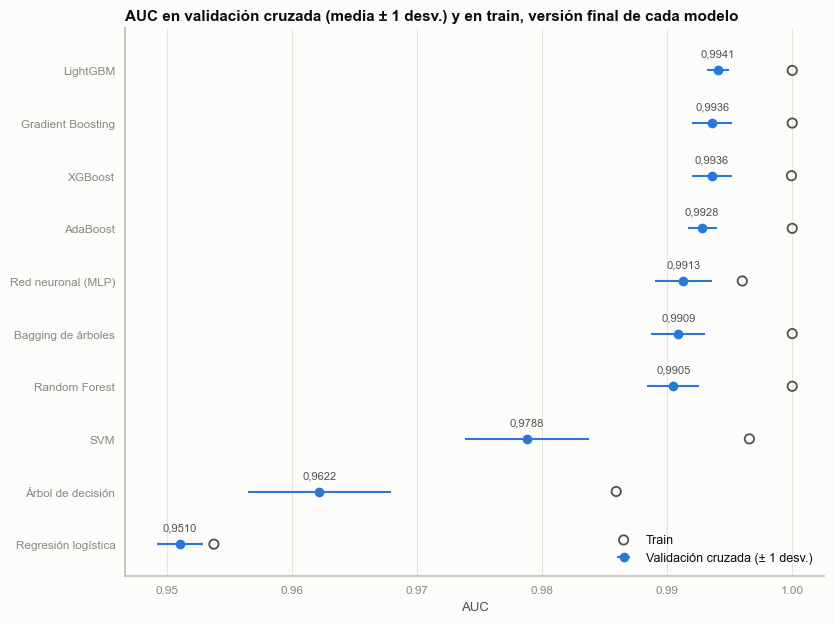

,diferencia_media,diferencia_desv,pliegues_por_debajo_del_mejor
modelo,,,
LightGBM,0.0000,0.0000,0
Gradient Boosting,-0.0005,0.0009,3
XGBoost,-0.0005,0.0007,3
AdaBoost,-0.0013,0.0007,5
Red neuronal (MLP),-0.0028,0.0018,5
Bagging de árboles,-0.0032,0.0014,5
Random Forest,-0.0036,0.0016,5
SVM,-0.0153,0.0047,5
Árbol de decisión,-0.0319,0.0049,5


Finalistas (a menos de 1 desviación del mejor): ['LightGBM', 'Gradient Boosting', 'XGBoost']


In [56]:
tabla_final_cv = comparador.tabla_cv()
reportes.guardar_tabla(tabla_final_cv[columnas_tabla], "modelado_tabla_cv")
display(tabla_final_cv[columnas_tabla].round(4))

fig = graficos_modelado.auc_cv_por_modelo(
    tabla_final_cv, "AUC en validación cruzada (media ± 1 desv.) y en train, versión final de cada modelo")
reportes.mostrar_figura(fig, "modelado_02_auc_cv_final")

pareada = comparador.comparacion_pareada()
reportes.guardar_tabla(pareada, "modelado_pareada")
display(pareada.round(4))
finalistas = comparador.finalistas()
print(f"Finalistas (a menos de 1 desviación del mejor): {finalistas}")

#### ¿Mejora combinar a los finalistas?

**Votación** (promedio de sus probabilidades) y **stacking** (una regresión logística aprende cuánto pesar a cada uno), en los mismos pliegues.

In [57]:
combinacion = comparacion.combinar_finalistas(
    {nombre: comparador.modelos[nombre].busqueda_.best_estimator_ for nombre in finalistas},
    particion.X_train, particion.y_train, referencia=tabla_final_cv.index[0])
reportes.guardar_tabla(combinacion, "modelado_combinacion_finalistas")
display(combinacion.round(5))

,auc_cv,auc_cv_desv,diferencia_vs_referencia,diferencia_desv,pliegues_que_mejoran,churners_20
combinacion,,,,,,
LightGBM,0.99407,0.00089,0.00000,0.00000,0,1275
Votación de finalistas,0.99400,0.00147,-0.00007,0.00063,3,1275
Stacking de finalistas,0.99390,0.00147,-0.00017,0.00063,3,1276


#### Lectura y decisión

- **LightGBM:** 0,9941 ± 0,0009, el mayor AUC y la menor variación.
- **Gradient Boosting y XGBoost empatan con él:** quedan a menos de 0,001 y no pierden en todos los pliegues. Los otros siete quedan por debajo en los 5 pliegues.
- **Combinar no mejora:** votación 0,99400 y stacking 0,99390, frente a 0,99407 de LightGBM. Los finalistas son de la misma familia y se equivocan con los mismos clientes.

**Decisión.** Pasan a test los tres finalistas y la logística como referencia interpretable. Preferencia preliminar: **LightGBM**; se confirma en 5.2.

### 4.8 Conclusión de la Fase 4

1. Se compararon los diez métodos del curso con el mismo protocolo: **boosting gana**, como había anticipado PyCaret.
2. Los finalistas usan 13 variables numéricas: categóricas, candidatas, SMOTE y pesos no mejoran su orden de los clientes.
3. La búsqueda se detuvo con un criterio y combinar modelos no aporta.

## CRISP-DM Fase 5: Evaluación

### 5.1 Desempeño en test

Los finalistas y la logística, reajustados con todo train, predicen a los 2.026 clientes de test. **Regla fijada antes de ver el test:** se elige LightGBM, salvo que otro finalista lo supere con un IC de 95 % (bootstrap) que excluya el 0. Las métricas de clasificación usan el umbral 0,5 para poder comparar; **no es la regla de operación**, que es por capacidad (5.4).

#### Coherencia con la Fase 4

In [58]:
evaluados = finalistas + ["Regresión logística"]
pipelines_finales = {nombre: comparador.modelos[nombre].busqueda_.best_estimator_ for nombre in evaluados}
for nombre in evaluados:
    print(f"{nombre}: {comparador.modelos[nombre].resumen()['mejores_hiperparametros']}")

cv = modelos.validacion_cruzada()
oof = evaluacion.oof_de_modelos(pipelines_finales, particion.X_train, particion.y_train, cv)
auc_cv_medio = {nombre: comparador.modelos[nombre].resumen()["auc_cv"] for nombre in evaluados}
resumen_oof = evaluacion.resumen_oof(oof, particion.y_train, auc_cv_medio)
reportes.guardar_tabla(resumen_oof, "evaluacion_coherencia_oof")
display(resumen_oof.round(4))

LightGBM: {'learning_rate': 0.03, 'n_estimators': 1000, 'num_leaves': 31}
Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400}
XGBoost: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600}
Regresión logística: {'C': 1, 'penalty': 'l1'}


,auc_oof,auc_cv_medio
LightGBM,0.9941,0.9941
Gradient Boosting,0.9934,0.9936
XGBoost,0.9935,0.9936
Regresión logística,0.9509,0.9510


#### Lectura y decisión

- El AUC de las predicciones fuera de pliegue coincide con el de la Fase 4 (diferencia de 0,0001 o menos): se evalúan los pipelines elegidos.
- Esas predicciones son la base de 5.4 a 5.7. Son levemente optimistas, porque los hiperparámetros se eligieron con los mismos pliegues; por eso el test confirma.

#### Predicción única en test

In [59]:
probabilidades_test = {nombre: pipe.predict_proba(particion.X_test)[:, 1] for nombre, pipe in pipelines_finales.items()}
y_test = particion.y_test
print(f"Clientes de test: {len(y_test):,} | churners: {int(y_test.sum())} ({y_test.mean():.2%})")
print(f"Baseline trivial en test (decir que nadie se va): accuracy {1 - y_test.mean():.2%}")

metricas_05 = evaluacion.metricas_en_test(y_test, probabilidades_test)  # umbral 0,5 para todos
reportes.guardar_tabla(metricas_05, "test_metricas_umbral_05", decimales=None)
columnas_metricas = ["auc", "ap", "log_loss", "brier", "accuracy", "sensibilidad", "precision", "f1", "tp", "fp"]
display(metricas_05[columnas_metricas].astype(float).round(4))  # la tabla completa queda en reports/tables

cv_vs_test = evaluacion.comparar_cv_test(resumen_oof, metricas_05)
reportes.guardar_tabla(cv_vs_test, "test_cv_vs_test")
display(cv_vs_test.round(4))

Clientes de test: 2,026 | churners: 325 (16.04%)
Baseline trivial en test (decir que nadie se va): accuracy 83.96%


,auc,ap,log_loss,brier,accuracy,sensibilidad,precision,f1,tp,fp
LightGBM,0.9930,0.9675,0.1037,0.0241,0.9699,0.8738,0.9342,0.9030,284.0,20.0
Gradient Boosting,0.9925,0.9671,0.0860,0.0238,0.9704,0.8585,0.9522,0.9029,279.0,14.0
XGBoost,0.9929,0.9675,0.0801,0.0230,0.9714,0.8585,0.9588,0.9058,279.0,12.0
Regresión logística,0.9445,0.8039,0.2072,0.0617,0.9210,0.6523,0.8185,0.7260,212.0,47.0


,auc_cv,auc_test,diferencia_test_menos_cv
LightGBM,0.9941,0.9930,-0.0011
Gradient Boosting,0.9936,0.9925,-0.0011
XGBoost,0.9936,0.9929,-0.0007
Regresión logística,0.9510,0.9445,-0.0065


#### Curvas ROC y PR, y matrices de confusión con el umbral 0,5

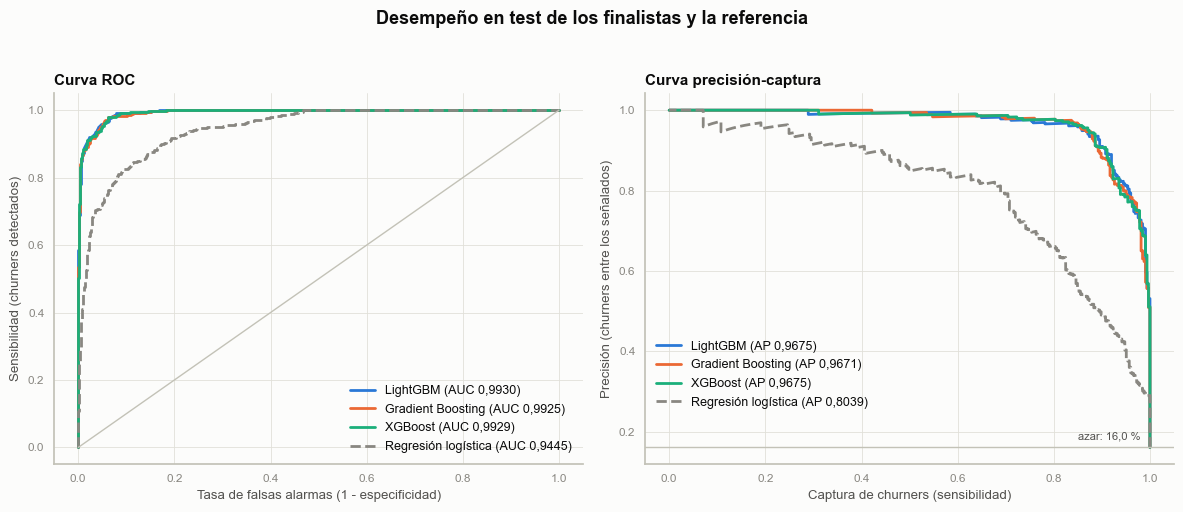

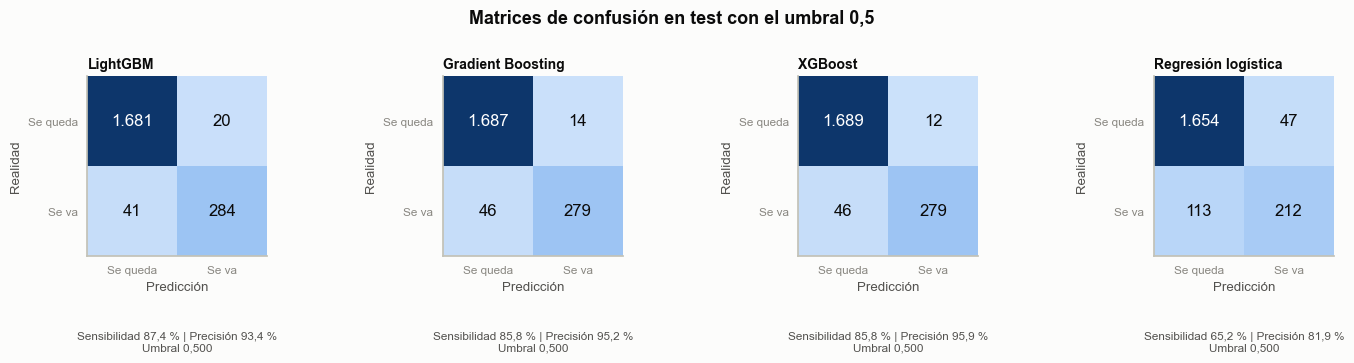

In [60]:
fig = graficos_modelado.curvas_roc_pr(y_test, probabilidades_test, "Desempeño en test de los finalistas y la referencia",
                                      referencia_gris="Regresión logística")
reportes.mostrar_figura(fig, "test_01_roc_pr")

resultados_05 = {n: evaluacion.calcular_metricas(y_test, p, 0.5) for n, p in probabilidades_test.items()}
fig = graficos_modelado.matrices_confusion(resultados_05, "Matrices de confusión en test con el umbral 0,5")
reportes.mostrar_figura(fig, "test_02_matrices_confusion");

#### Lectura y decisión

- **El test confirma la validación cruzada:** AUC de 0,9930 en LightGBM y 0,9445 en la logística (caídas de 0,0011 y 0,0065): no hay sobreajuste a los pliegues.
- **Con el umbral 0,5,** LightGBM detecta 284 de los 325 churners (sensibilidad de 87,38 %; precisión de 93,42 %) y la logística 212 (65,23 %).
- **Por qué el AUC es tan alto:** el objetivo sale de `attrition_flag`, que se elimina antes de modelar, y ninguna variable sola delata el resultado (AUC univariado máximo de 0,796): la cifra sale de combinar las variables de actividad (5.6). Lo que no se puede descartar es que esa actividad se haya medido cerca del retiro (5.8).
- **LightGBM es algo sobreconfiado** (log loss de 0,1037, el más alto de los finalistas); se revisa en 5.3.

### 5.2 ¿Las diferencias son reales? Bootstrap pareado

Se remuestrean los 2.026 clientes de test 2.000 veces, con la misma proporción de churners, y se recalcula el AUC de los cuatro modelos sobre los mismos clientes: IC de 95 % para cada AUC y para su diferencia contra LightGBM.

In [61]:
tabla_bootstrap = evaluacion.bootstrap_auc(y_test, probabilidades_test, referencia="LightGBM",
                                           n_remuestras=2000, semilla=config.SEMILLA)
reportes.guardar_tabla(tabla_bootstrap, "test_bootstrap_auc")
display(tabla_bootstrap.round(4))

# Lo que mide el banco: churners capturados con cada capacidad, en train (fuera de pliegue) y en test
captura_modelos = pd.concat({"train fuera de pliegue": negocio.escenarios_por_modelo(particion.y_train, oof),
                             "test": negocio.escenarios_por_modelo(y_test, probabilidades_test)}, axis=1)
reportes.guardar_tabla(captura_modelos, "test_captura_por_modelo")
print(f"Churners capturados con el 20 % de contacto (de {int(particion.y_train.sum()):,} en train y {int(y_test.sum())} en test):")
display(captura_modelos.xs("churners_20", axis=1, level=1))

,auc_test,auc_ic95_inf,auc_ic95_sup,dif_vs_referencia,dif_ic95_inf,dif_ic95_sup,prop_remuestras_mejor_que_ref,equivalente_a_referencia
modelo,,,,,,,,
LightGBM,0.9930,0.9903,0.9954,0.0000,0.0000,0.0000,0.000,True
Gradient Boosting,0.9925,0.9895,0.9951,-0.0005,-0.0017,0.0007,0.212,True
XGBoost,0.9929,0.9902,0.9953,-0.0001,-0.0010,0.0008,0.401,True
Regresión logística,0.9445,0.9323,0.9550,-0.0485,-0.0598,-0.0385,0.000,False


Churners capturados con el 20 % de contacto (de 1,302 en train y 325 en test):


,train fuera de pliegue,test
LightGBM,1275.0,313.0
Gradient Boosting,1272.0,314.0
XGBoost,1270.0,313.0
Regresión logística,1076.0,263.0


#### Lectura y decisión

- **XGBoost y Gradient Boosting no se distinguen de LightGBM** (AUC de 0,9930; IC 95 % de 0,9903 a 0,9954): el intervalo de su diferencia incluye el 0. La logística queda 0,0485 por debajo (IC de -0,0598 a -0,0385).
- **En la métrica del banco tampoco:** con el 20 % de contacto, LightGBM captura 1.275 de 1.302 churners en train y 313 de 325 en test; los otros dos finalistas quedan a menos de 10 clientes, y la logística en 1.076 y 263.

**Decisión, según la regla previa: el modelo final es LightGBM.** Ningún finalista lo supera y además tiene la menor variación entre pliegues.

### 5.3 Calibración: ¿la probabilidad significa lo que dice?

Las decisiones usan el **orden** de los clientes, no el valor de la probabilidad. La calibración solo importa si el banco quisiera leerla como un porcentaje literal. Se revisa por deciles; el **Brier** (error cuadrático de la probabilidad) lo resume en un número.

,error_calibracion,error_calibracion_oof_train,brier,prob_media_predicha,tasa_real
LightGBM,0.0122,0.0102,0.0241,0.1500,0.1604
Gradient Boosting,0.0145,0.0089,0.0238,0.1480,0.1604
XGBoost,0.0113,0.0067,0.0230,0.1500,0.1604
Regresión logística,0.0099,0.0046,0.0617,0.1529,0.1604


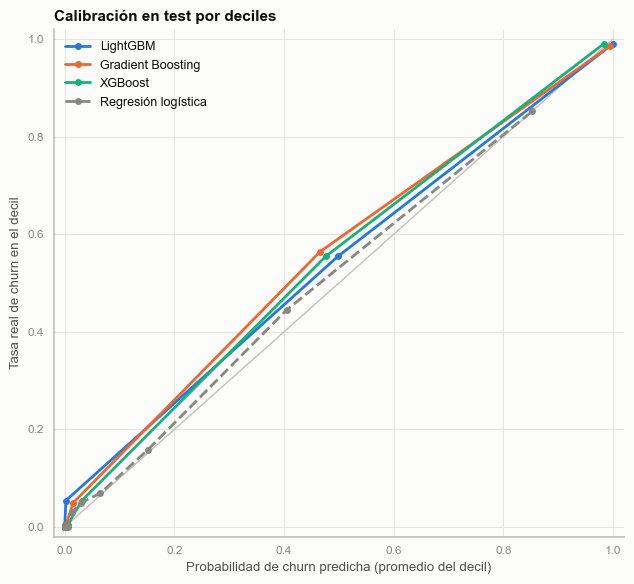

In [62]:
tablas_calibracion = {n: evaluacion.tabla_calibracion(y_test, p) for n, p in probabilidades_test.items()}
resumen_calibracion = pd.DataFrame({
    "error_calibracion": {n: evaluacion.error_calibracion(t) for n, t in tablas_calibracion.items()},
    "error_calibracion_oof_train": {n: evaluacion.error_calibracion(evaluacion.tabla_calibracion(particion.y_train, p))
                                    for n, p in oof.items()},
    "brier": metricas_05["brier"].astype(float),
    "prob_media_predicha": {n: float(np.mean(p)) for n, p in probabilidades_test.items()},
    "tasa_real": float(y_test.mean()),
})
reportes.guardar_tabla(resumen_calibracion, "test_calibracion")
display(resumen_calibracion.round(4))
reportes.guardar_tabla(tablas_calibracion["LightGBM"], "test_calibracion_deciles_lightgbm")

fig = graficos_modelado.diagrama_calibracion(tablas_calibracion, "Calibración en test por deciles",
                                             referencia_gris="Regresión logística")
reportes.mostrar_figura(fig, "test_03_calibracion");

#### Lectura y decisión

- **Por deciles el error es pequeño** (0,0122 en LightGBM), aunque la medida se diluye porque la mayoría de los deciles tiene probabilidad y churn cercanos a 0. El Brier de la logística (0,0617) es más del doble que el de LightGBM (0,0241).
- **LightGBM predice en promedio 15,00 % y se va el 16,04 %:** subestima un poco.

**Decisión.** No se recalibra, porque no cambiaría el orden de los clientes (mejora posible, 6.4).

### 5.4 Escenarios de contacto

Se ordena a los clientes por probabilidad y se contacta al top k %; la probabilidad del último contactado es el **umbral implícito**. Se decide con las predicciones **fuera de pliegue en train** (8.101 clientes) y el test (2.026) confirma.

#### Escenarios con train fuera de pliegue

In [63]:
modelo_final = "LightGBM"
escenarios_oof = negocio.tabla_escenarios(particion.y_train, oof[modelo_final])
incremental_oof = negocio.tabla_incremental(escenarios_oof)
reportes.guardar_tabla(escenarios_oof, "negocio_escenarios_oof")
reportes.guardar_tabla(incremental_oof, "negocio_incremental_oof")
display(escenarios_oof.round(4))
display(incremental_oof.round(4))

escenarios_oof_logistica = negocio.tabla_escenarios(particion.y_train, oof["Regresión logística"])
reportes.guardar_tabla(escenarios_oof_logistica, "negocio_escenarios_oof_logistica")  # referencia (tabla de 5.2);

,contactados,churners_capturados,captura,precision,lift,beneficios_a_no_churners,churners_sin_contactar,umbral_implicito,captura_maxima_posible
capacidad,,,,,,,,,
0.1,810,799,0.6137,0.9864,6.1375,11,503,0.9981,0.6221
0.2,1620,1275,0.9793,0.7870,4.8969,345,27,0.0072,1.0000
0.3,2430,1296,0.9954,0.5333,3.3184,1134,6,0.0001,1.0000


,contactos_adicionales,churners_adicionales,precision_marginal
capacidad,,,
0.1,810,799,0.9864
0.2,810,476,0.5877
0.3,810,21,0.0259


WindowsPath('C:/Users/PERSONAL/Projects/U-Analitica II/Proyecto Final Analitica II/Trabajo Juanfer & Juandi/reports/tables/negocio_escenarios_oof_logistica.csv')

#### Lectura y decisión (train, fuera de pliegue)

- **Con el 10 % casi no hay desperdicio** (precisión de 98,64 %), pero solo se cubre el 61,37 % de los churners; **el 20 % cubre casi todo** (97,93 %, 1.275 de 1.302 con 1.620 contactos).
- **Pasar a 30 %** agrega 810 contactos que encuentran solo 21 churners (precisión marginal de 2,59 %, frente a 58,77 % del paso de 10 % a 20 %).
- Con el mismo 20 %, LightGBM captura 199 churners más que la logística (5.2).

#### Confirmación en test con intervalos de confianza

,contactados,churners_capturados,captura,precision,lift,beneficios_a_no_churners,churners_sin_contactar,umbral_implicito,captura_maxima_posible,captura_ic95_inf,captura_ic95_sup,precision_ic95_inf,precision_ic95_sup
capacidad,,,,,,,,,,,,,
0.1,203,201,0.6185,0.9901,6.1724,2,124,0.9953,0.6246,0.6062,0.6246,0.9704,1.0000
0.2,405,313,0.9631,0.7728,4.8178,92,12,0.0136,1.0000,0.9415,0.9815,0.7556,0.7877
0.3,608,324,0.9969,0.5329,3.3220,284,1,0.0002,1.0000,0.9908,1.0000,0.5296,0.5345


Tabla de ganancia por deciles de riesgo en test (decil 1 = 10 % de mayor riesgo):


,clientes,churners,tasa_churn,lift,captura_acumulada,prob_min,prob_max
decil,,,,,,,
1,203,201,0.9901,6.1724,0.6185,0.9953,1.0000
2,203,112,0.5517,3.4394,0.9631,0.0133,0.9951
3,203,11,0.0542,0.3378,0.9969,0.0002,0.0127
4,203,1,0.0049,0.0307,1.0000,0.0000,0.0002
5,203,0,0.0000,0.0000,1.0000,0.0000,0.0000
6,203,0,0.0000,0.0000,1.0000,0.0000,0.0000
7,202,0,0.0000,0.0000,1.0000,0.0000,0.0000
8,202,0,0.0000,0.0000,1.0000,0.0000,0.0000
9,202,0,0.0000,0.0000,1.0000,0.0000,0.0000


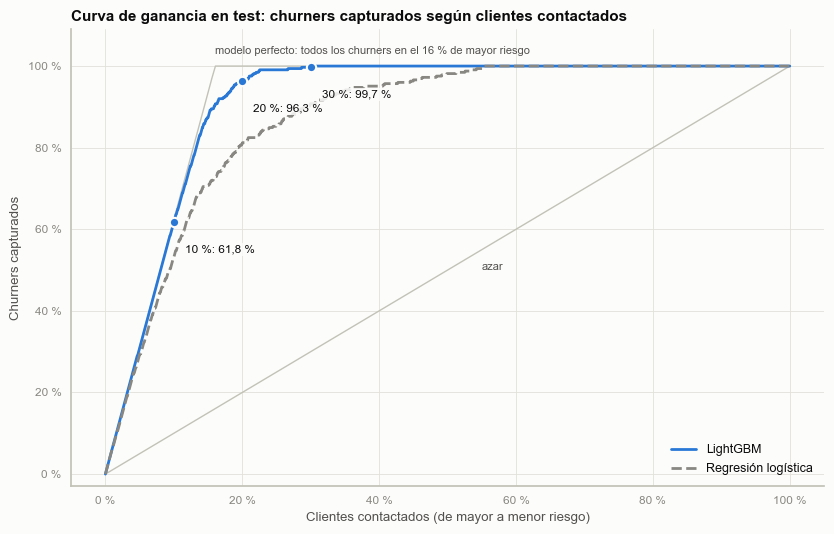

In [64]:
lectura = negocio.lectura_test(y_test, probabilidades_test[modelo_final], n_remuestras=2000)
escenarios_test, incremental_test = lectura["escenarios"], lectura["incremental"]
ic_escenarios, deciles_test = lectura["intervalos"], lectura["deciles"]
reportes.guardar_tabla(escenarios_test, "negocio_escenarios_test")
reportes.guardar_tabla(incremental_test, "negocio_incremental_test")
reportes.guardar_tabla(ic_escenarios, "negocio_ic_escenarios_test")
reportes.guardar_tabla(deciles_test, "negocio_deciles_test")
display(escenarios_test.join(ic_escenarios).round(4))  # el incremental de test se lee en los deciles 2 y 3
print("Tabla de ganancia por deciles de riesgo en test (decil 1 = 10 % de mayor riesgo):")
display(deciles_test.round(4))

fig = graficos_negocio.curvas_ganancia(
    {modelo_final: negocio.curva_ganancia(y_test, probabilidades_test[modelo_final]),
     "Regresión logística": negocio.curva_ganancia(y_test, probabilidades_test["Regresión logística"])},
    tasa_churn=float(y_test.mean()), capacidades=config.ESCENARIOS_CAPACIDAD,
    titulo="Curva de ganancia en test: churners capturados según clientes contactados",
    principal=modelo_final, referencia_gris="Regresión logística")
reportes.mostrar_figura(fig, "negocio_01_curva_ganancia");

#### Lectura y decisión (test)

- **El test confirma:** con el 20 %, 313 de 405 contactados son churners (captura de 96,31 %, IC 95 % de 94,15 % a 98,15 %; precisión de 77,28 %).
- **Riesgo muy concentrado:** el decil 1 tiene 99,01 % de churn, el decil 3 solo 5,42 % y desde el decil 5 no hay churners.
- **El umbral implícito es muy bajo** (0,0136 en el 20 %): se selecciona **por ranking**, no por un umbral de probabilidad (5.3).

### 5.5 Regla económica: ¿hasta dónde conviene contactar?

El caso no informa costos, márgenes ni tasa de éxito, así que se deja una **regla** que el banco aplica con sus cifras. `s` es la fracción de churners contactados que se queda gracias al beneficio; `r = V / c` es cuántas veces vale un cliente retenido (`V`) frente al costo de contactarlo y darle el beneficio (`c`). **Ampliar a un tramo más conviene si `s · r > 1 / precisión marginal` del tramo.**

| Supuesto de operación | Qué se asume |
|---|---|
| Ciclo | Una vez al año, con las variables de los últimos 12 meses, como en el caso |
| Volumen | El 20 % de la base activa por ciclo; si el área de atención no alcanza, el 10 % |
| Costo `c` | Contacto más beneficio, pagado por cada contactado, se vaya o no |
| Valor `V` | Lo que deja un cliente retenido en el mismo horizonte de un año |
| Éxito `s` | Igual para todos; puede ser menor en los de mayor riesgo, que quizá ya decidieron irse |
| Oportunidad | El contacto llega antes del retiro |
| Sin efecto negativo | Contactar a quien no se iba no lo empuja a irse |
| Un contacto por cliente | Un ofrecimiento por ciclo, en el orden del ranking |

Los supuestos se validan con el banco y con un piloto (6.4).

#### Cortes de la regla

In [65]:
cortes = negocio.tabla_cortes(incremental_oof, tasa_exito_ejemplo=0.5)
reportes.guardar_tabla(cortes, "negocio_cortes_oof")
display(cortes.round(4))

,contactos_adicionales,churners_adicionales,precision_marginal,sr_minimo,r_minimo_ejemplo
capacidad,,,,,
0.1,810,799,0.9864,1.0138,2.0275
0.2,810,476,0.5877,1.7017,3.4034
0.3,810,21,0.0259,38.5714,77.1429


#### Lectura y decisión

- **Cortes de s · r:** bajo 1,01 no conviene contactar; de 1,01 a 1,70 conviene el 10 %; de 1,70 a 38,57, el 20 %; por encima, el 30 %.
- **Ejemplo:** si la mitad de los churners contactados se queda (s = 0,5), el 20 % conviene cuando un cliente retenido vale al menos 3,40 veces el costo del beneficio.

**Decisión. Si s · r está entre 1,70 y 38,57, contactar en cada ciclo al 20 % de mayor riesgo:** captura 98 de cada 100 churners con un volumen apenas mayor que la tasa de churn. El rango es amplio: la recomendación resiste errores grandes al estimar `s` y `r`.

### 5.6 Importancia y dependencia

Con train y los mismos 5 pliegues; el test no se reutiliza. **Ganancia:** cuánto reduce el error cada variable en los árboles. **Permutación:** cuánto cae el AUC al desordenar una variable. La importancia es relativa y **no causal**.

#### Importancia de variables del modelo final

,caida_auc_media,caida_auc_desv,pliegues_con_caida,importancia_ganancia_pct,ranking_permutacion,ranking_ganancia
total_trans_ct,0.1529,0.0063,5,26.0980,1,1
total_trans_amt,0.0872,0.0060,5,21.9842,2,2
total_relationship_count,0.0088,0.0015,5,7.6158,3,5
total_amt_chng_q4_q1,0.0085,0.0021,5,7.4791,4,6
total_ct_chng_q4_q1,0.0056,0.0015,5,8.4507,5,4
total_revolving_bal,0.0055,0.0009,5,13.1966,6,3
months_inactive_12_mon,0.0023,0.0004,5,2.3385,7,9
customer_age,0.0023,0.0009,5,3.6736,8,7
credit_limit,0.0015,0.0008,5,3.2602,9,8
contacts_count_12_mon,0.0014,0.0003,5,1.6994,10,11


Peso de las 4 variables de actividad transaccional en la ganancia: 64.01 %
Variables que usa el modelo: 13 (ninguna categórica: True)


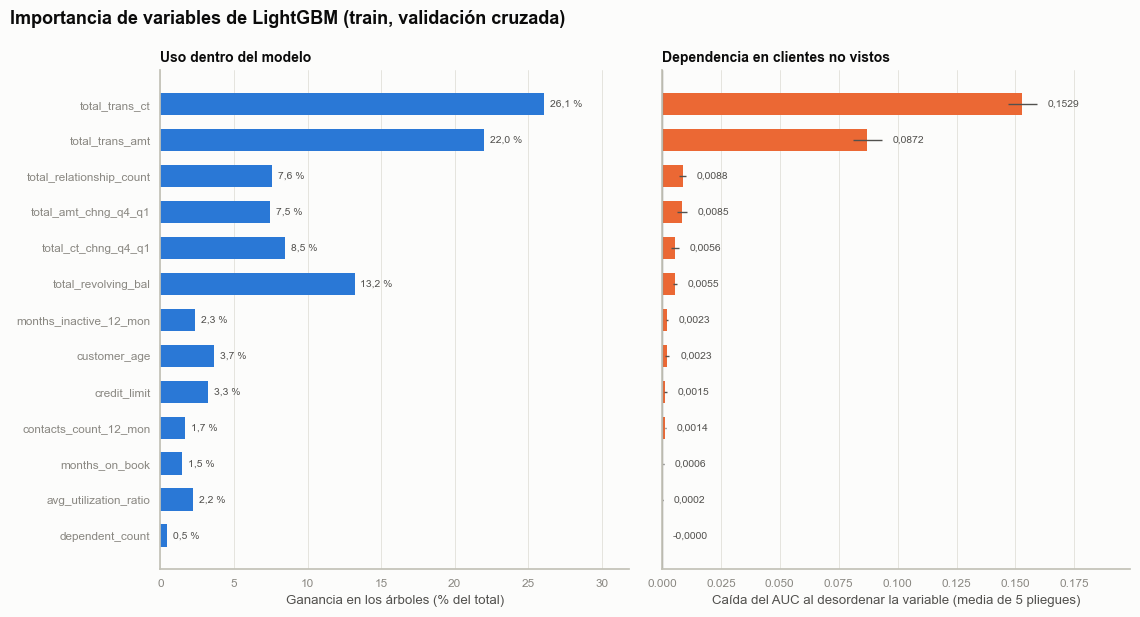

In [66]:
pipeline_final = pipelines_finales[modelo_final]
importancia_ganancia = explicabilidad.importancia_ganancia(pipeline_final)
importancia_permutacion = explicabilidad.importancia_permutacion_cv(
    pipeline_final, particion.X_train, particion.y_train, cv, n_repeticiones=5)

importancia = explicabilidad.tabla_importancia(importancia_permutacion, importancia_ganancia)
reportes.guardar_tabla(importancia, "explicabilidad_importancia")
display(importancia.round(4))

actividad = ["total_trans_ct", "total_trans_amt", "total_ct_chng_q4_q1", "total_amt_chng_q4_q1"]
print(f"Peso de las 4 variables de actividad transaccional en la ganancia: {importancia_ganancia[actividad].sum():.2f} %")
print(f"Variables que usa el modelo: {len(importancia_ganancia)} (ninguna categórica: {not set(datos.COLUMNAS_CATEGORICAS) & set(importancia_ganancia.index)})")

fig = graficos_negocio.importancia_variables(importancia_ganancia, importancia_permutacion,
                                             "Importancia de variables de LightGBM (train, validación cruzada)")
reportes.mostrar_figura(fig, "explicabilidad_01_importancia");

#### Lectura y decisión

- **La actividad es la señal de alerta:** desordenar `total_trans_ct` y `total_trans_amt` baja el AUC en 0,1529 y 0,0872; las cuatro variables de actividad suman 64,01 % de la ganancia. Ninguna otra baja el AUC más de 0,01.
- **El modelo usa 13 variables y ninguna es categórica de perfil** (4.3).

**Lectura de negocio.** Importa **cómo cambia el uso de la tarjeta**, no quién es el cliente: una señal que se puede vigilar en cada lote.

#### Dependencia parcial de las variables principales

Probabilidad de churn promedio si todos los clientes tuvieran el valor *x* de la variable (puestos 3 a 8 del ranking de permutación).

Variables de los puestos 3 a 8 del ranking de permutación: ['total_relationship_count', 'total_amt_chng_q4_q1', 'total_ct_chng_q4_q1', 'total_revolving_bal', 'months_inactive_12_mon', 'customer_age']
total_relationship_count   de     1.00 a     6.00: prob. de 25.70% a 15.03% (mín. 15.03%, máx. 25.70%)
total_amt_chng_q4_q1       de     0.34 a     1.51: prob. de 21.12% a 9.47% (mín. 9.47%, máx. 21.12%)
total_ct_chng_q4_q1        de     0.23 a     1.50: prob. de 19.50% a 11.55% (mín. 11.53%, máx. 19.50%)
total_revolving_bal        de     0.00 a  2517.00: prob. de 17.60% a 17.12% (mín. 13.65%, máx. 18.60%)
months_inactive_12_mon     de     0.00 a     6.00: prob. de 16.00% a 16.09% (mín. 14.14%, máx. 16.45%)
customer_age               de    27.00 a    65.00: prob. de 8.66% a 16.04% (mín. 8.66%, máx. 16.62%)


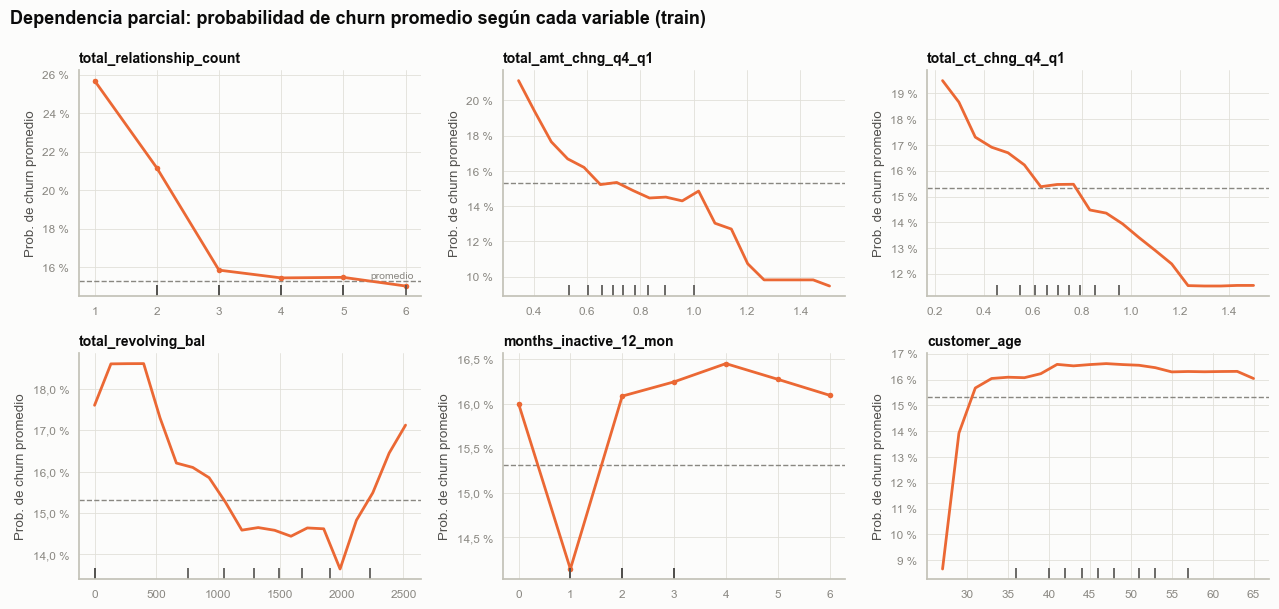

In [67]:
siguientes = list(importancia_permutacion.index[2:8])
assert not set(siguientes) & set(datos.COLUMNAS_CATEGORICAS), "la dependencia parcial 1D se dibuja solo para numéricas"
print(f"Variables de los puestos 3 a 8 del ranking de permutación: {siguientes}")
dependencias = explicabilidad.dependencia_parcial(pipeline_final, particion.X_train, siguientes, puntos=20)
reportes.guardar_tabla(pd.concat(dependencias, names=["variable", "punto"]), "explicabilidad_dependencia_parcial")
for variable, curva in dependencias.items():
    extremos = curva["prob_churn_media"]
    print(f"{variable:<26} de {curva['valor'].iloc[0]:>8.2f} a {curva['valor'].iloc[-1]:>8.2f}: "
          f"prob. de {extremos.iloc[0]:.2%} a {extremos.iloc[-1]:.2%} (mín. {extremos.min():.2%}, máx. {extremos.max():.2%})")

prob_media_train = float(oof[modelo_final].mean())
fig = graficos_negocio.dependencias_parciales(
    dependencias, particion.X_train, prob_media_train,
    "Dependencia parcial: probabilidad de churn promedio según cada variable (train)")
reportes.mostrar_figura(fig, "explicabilidad_02_dependencia_parcial");

#### Mapa conjunto de monto y transacciones

Están muy correlacionadas (0,88): moverlas por separado crea clientes inexistentes, así que se analizan juntas y se dejan en blanco las celdas con menos de 10 clientes.

Celdas con al menos 10 clientes: 74 de 256, con 7,856 de 8,101 clientes de train
Rango de la probabilidad promedio por tramo de monto del EDA (solo celdas con datos):


,celdas,prob_min,prob_max,clientes
total_trans_amt,,,,
hasta 3.000,21,0.0024,0.6654,3407
3.001 a 6.000,18,0.0002,0.4069,3465
6.001 a 11.000,18,0.0038,0.7672,492
más de 11.000,17,0.0006,0.0272,492


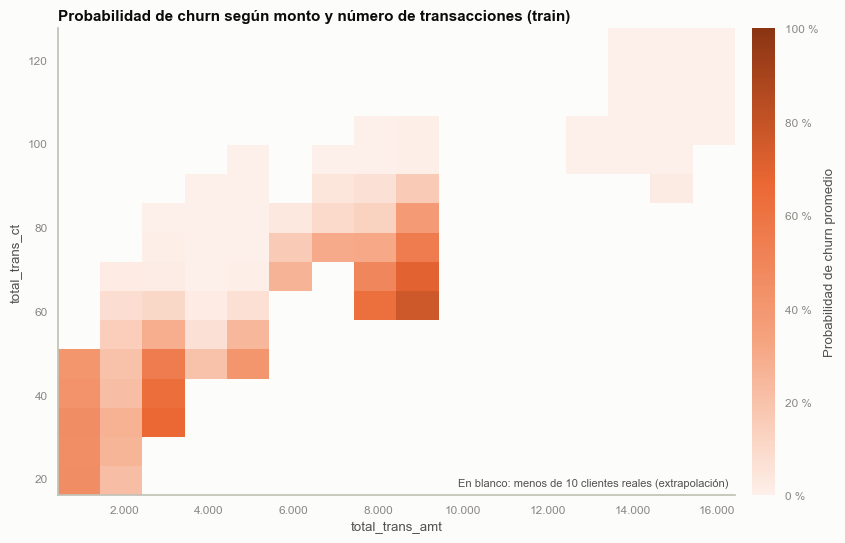

In [68]:
conjunta = explicabilidad.dependencia_parcial_2d(pipeline_final, particion.X_train, "total_trans_amt", "total_trans_ct",
                                                 puntos=16, muestra=2000)
reportes.guardar_tabla(conjunta, "explicabilidad_monto_frecuencia", indice=False)
con_datos, resumen_tramos = explicabilidad.resumir_tramos(conjunta)
reportes.guardar_tabla(resumen_tramos, "explicabilidad_monto_frecuencia_tramos")
print(f"Celdas con al menos 10 clientes: {len(con_datos)} de {len(conjunta)}, "
      f"con {con_datos['clientes_en_celda'].sum():,} de {len(particion.X_train):,} clientes de train")
print("Rango de la probabilidad promedio por tramo de monto del EDA (solo celdas con datos):")
display(resumen_tramos.round(4))

fig = graficos_negocio.dependencia_parcial_conjunta(conjunta, "total_trans_amt", "total_trans_ct",
                                                    "Probabilidad de churn según monto y número de transacciones (train)")
reportes.mostrar_figura(fig, "explicabilidad_03_monto_frecuencia");

#### Lectura y decisión

- **El mapa explica los segmentos del EDA:** a igual monto, el modelo da mucho más riesgo a quien hace menos transacciones; sobre 11.000 ninguna celda con datos supera 2,72 %.
- **Las demás variables mueven poco la probabilidad promedio:** la caída del monto entre trimestres la sube hasta 21,12 %; un solo producto, hasta 25,70 %.
- **Edad:** 8,66 % a los 27 años y cerca de 16 % en adelante. Describe lo que aprendió el modelo; no es una regla para tratar distinto por edad (5.8).

### 5.7 Sensibilidad y equidad

Según el caso, las variables son de 2021 y el retiro se observa al cierre de 2022. Aun así, los 42 clientes con 6 contactos se fueron todos (2.6) y el archivo no trae fechas para confirmar el orden de los hechos. Se reentrena el **mismo pipeline** sin `contacts_count_12_mon` y se compara pliegue a pliegue.

#### Sensibilidad a la variable de contactos

In [69]:
sensibilidad, oof_variantes = explicabilidad.sensibilidad_variables(
    pipeline_final, particion.X_train, particion.y_train, cv, explicabilidad.VARIANTES_SENSIBILIDAD)

# Control: la variante completa debe reproducir exactamente las predicciones fuera de pliegue de 5.1
diferencia_control = np.abs(oof_variantes["completo"] - oof[modelo_final]).max()
assert diferencia_control < 1e-12, diferencia_control
print(f"Control: la variante completa reproduce las predicciones de 5.1 (diferencia máxima {diferencia_control:.1e})")

sensibilidad = explicabilidad.agregar_escenarios(sensibilidad, particion.y_train, oof_variantes)
reportes.guardar_tabla(sensibilidad, "explicabilidad_sensibilidad")
display(sensibilidad.round(5))

Control: la variante completa reproduce las predicciones de 5.1 (diferencia máxima 0.0e+00)


,variables_quitadas,auc_cv,auc_cv_desv,diferencia_vs_completo,diferencia_desv,pliegues_por_debajo,churners_10,captura_10,precision_10,churners_20,captura_20,precision_20
variante,,,,,,,,,,,,
completo,ninguna,0.99407,0.00089,0.00000,0.00000,0,799.0,0.61367,0.98642,1275.0,0.97926,0.78704
sin contactos,contacts_count_12_mon,0.99333,0.00112,-0.00074,0.00053,4,798.0,0.61290,0.98519,1270.0,0.97542,0.78395


#### Los 42 clientes con 6 contactos

In [70]:
seis_contactos = particion.X_train["contacts_count_12_mon"] == 6
grupo_seis = explicabilidad.seleccion_en_grupo(
    particion.y_train, {k: oof_variantes[k] for k in ("completo", "sin contactos")}, seis_contactos, capacidad=0.2)
reportes.guardar_tabla(grupo_seis, "explicabilidad_seis_contactos")
display(grupo_seis.round(4))

,clientes,churners,prob_media,prob_minima,dentro_del_escenario
variante,,,,,
completo,42,42,0.9501,0.0196,42
sin contactos,42,42,0.8387,0.0002,40


#### Lectura y decisión

- **Quitar `contacts_count_12_mon` cuesta 0,00074 de AUC** (de 0,99407 a 0,99333; más bajo en 4 de 5 pliegues) y 5 churners con el 20 % (1.270 frente a 1.275).
- De los 42 clientes con 6 contactos, 40 siguen dentro del 20 % sin ella: el modelo no depende de esa regla.

**Decisión.** Se conserva la variable: el caso la entrega como dato de 2021 y el banco la tiene al puntuar. Si el banco confirmara que incluye el trámite de retiro, la versión sin ella rinde casi igual y `produccion.construir_pipeline_alternativo` la reconstruye.

#### Trato por sexo y por edad en el escenario de 20 %

Que el modelo no reciba `gender` no garantiza un trato igual. Por grupo se revisa qué parte se contacta, la captura, la precisión y la **proporcionalidad al riesgo real** (`razon_contacto_riesgo`: porcentaje contactado dividido por la tasa real de churn del grupo). Es una revisión descriptiva, no una auditoría completa de equidad.

In [72]:
equidad = pd.concat({nombre: explicabilidad.equidad_por_grupo(particion.y_train, oof_variantes[nombre],
                                                              particion.X_train["gender"], capacidad=0.2)
                     for nombre in ("completo", "sin contactos")},
                    names=["variante", "grupo"])
reportes.guardar_tabla(equidad, "explicabilidad_equidad_sexo")
display(equidad.round(4))

brecha_sexo = explicabilidad.ic_brecha_captura(particion.y_train, oof_variantes["completo"], particion.X_train["gender"],
                                               capacidad=0.2, n_remuestras=2000, semilla=config.SEMILLA)
reportes.guardar_tabla(brecha_sexo, "explicabilidad_brecha_captura_sexo")
display(brecha_sexo.round(4))

tramo_edad = exploracion.tramos(particion.X_train["customer_age"], *explicabilidad.TRAMOS_EDAD)
equidad_edad = pd.concat({nombre: explicabilidad.equidad_por_grupo(particion.y_train, oof_variantes[nombre], tramo_edad,
                                                                   capacidad=0.2).loc[explicabilidad.TRAMOS_EDAD[1]]
                          for nombre in ("completo", "sin contactos")}, names=["variante", "grupo"])
reportes.guardar_tabla(equidad_edad, "explicabilidad_equidad_edad")
print("Trato por tramo de edad (años) en el escenario de 20 %:")
display(equidad_edad.round(4))

clientes  churners  tasa_churn_real  pct_contactado  captura_en_grupo  precision_en_grupo  razon_contacto_riesgo
variante      grupo                                                                                                                  
completo      F          4272       749           0.1753          0.2058            0.9880              0.8419                 1.1736
              M          3829       553           0.1444          0.1935            0.9675              0.7220                 1.3400
sin contactos F          4272       749           0.1753          0.2058            0.9853              0.8396                 1.1736
              M          3829       553           0.1444          0.1935            0.9620              0.7179                 1.3400

,churners_F,churners_M,brecha_captura,ic95_inf,ic95_sup,incluye_cero
comparacion,,,,,,
F menos M,749,553,0.0205,0.0043,0.0372,False


Trato por tramo de edad (años) en el escenario de 20 %:


clientes  churners  tasa_churn_real  pct_contactado  captura_en_grupo  precision_en_grupo  razon_contacto_riesgo
variante      grupo                                                                                                                      
completo      hasta 35        720        90           0.1250          0.1597            0.9778              0.7652                 1.2778
              36 a 45        2974       489           0.1644          0.2058            0.9796              0.7827                 1.2515
              46 a 55        3320       556           0.1675          0.2057            0.9802              0.7980                 1.2284
              más de 55      1087       167           0.1536          0.1932            0.9760              0.7762                 1.2575
sin contactos hasta 35        720        90           0.1250          0.1597            0.9667              0.7565                 1.2778
              36 a 45        2974       489           0.1644          0.2065            0.9796              0.7801                 1.2556
              46 a 55        3320       556           0.1675          0.2039            0.9730              0.7991                 1.2176
              más de 55      1087       167           0.1536          0.1969            0.9760              0.7617                 1.2814

#### Lectura y decisión (escenario de 20 %, train fuera de pliegue)

- **Captura:** 98,80 % en mujeres y 96,75 % en hombres. La brecha de 2,05 puntos tiene un IC 95 % de 0,43 a 3,72: es real, aunque pequeña, y existe aunque el modelo no usa el sexo.
- **No viene de contactar menos a los hombres:** se les contacta más en proporción a su riesgo (razón de 1,34 frente a 1,17). Su precisión es menor (72,20 % frente a 84,19 %), en parte porque su tasa de churn es más baja.
- **Por edad el trato es parejo:** captura de 97,60 % a 98,02 % y razón de 1,23 a 1,28 en los cuatro tramos.

**Lectura de negocio.** La causa de la brecha no se puede atribuir con estos datos (sexo e ingresos no son independientes, 2.8). Se vigila en el monitoreo y no se sacan conclusiones comerciales por sexo.

### 5.8 Riesgos y limitaciones

| Riesgo | Evidencia | Mitigación |
|---|---|---|
| Momento de medición de las variables | AUC de 0,99; 42 de 42 clientes con 6 contactos se fueron (2.6) | Confirmar con el banco que actividad y contactos se miden antes del retiro |
| Dependencia de `contacts_count_12_mon` | Quitarla cuesta 0,00074 de AUC (5.7) | Si incluye el trámite de retiro, usar la versión sin ella |
| Brecha de captura por sexo | 2,05 puntos menos en hombres (5.7) | Vigilarla y revisar su origen con el banco |
| Uso de la edad | Menor riesgo en los más jóvenes (5.6) | Validar con cumplimiento |
| Probabilidad no calibrada | 5.3 | Seleccionar por ranking |
| Predice quién se va, no quién responde al beneficio | 5.4 | Piloto con grupo de control |
| Validación en el mismo período | El archivo no trae fechas | El AUC de test es optimista para años futuros: confirmarlo en el primer ciclo real (6.3) |
| Segunda evaluación en test | El test se evaluó con el procedimiento inicial y con el final; la selección de variables (4.3) se decidió solo con train | El resultado sigue siendo de clientes no usados para decidir, pero no es una primera lectura |
| Supuestos | Capacidades, `s` y `r` (5.5); los lotes de 6.2 y 6.3 son clientes de train | La regla depende de los supuestos; 6.2 y 6.3 muestran la mecánica |

### 5.9 Conclusiones y decisión

1. **El modelo elegido es LightGBM,** con 13 variables numéricas: AUC de 0,9930 en test (IC 95 % de 0,9903 a 0,9954), a 0,0011 de la validación cruzada. XGBoost y Gradient Boosting no se distinguen de él (5.2); la logística (0,9445) es peor de forma significativa.
2. **Con el 20 % de contacto captura 313 de los 325 churners de test** (96,31 %; precisión de 77,28 %) (5.4).
3. **Recomendación:** si s · r está entre 1,70 y 38,57, contactar en cada ciclo al 20 % de mayor riesgo de la base activa, por ranking (5.5).
4. **Qué usa el modelo:** el comportamiento, no el perfil. La actividad transaccional suma 64,01 % de la ganancia y ninguna variable categórica de perfil entra al modelo (4.3 y 5.6).
5. **Un solo modelo:** el que se evaluó en test es el que se guarda y se usa para puntuar (6.1).

Los riesgos y limitaciones quedan en 5.8.

## CRISP-DM Fase 6: Despliegue, monitoreo y control

### 6.1 Modelo viable

Viable significa que se usa fuera del notebook con los mismos resultados y con controles que eviten puntuar datos rotos. Se guarda **un solo modelo**: el LightGBM evaluado en test, en `models/modelo_oficial.joblib`, con hiperparámetros fijos (`produccion.HIPERPARAMETROS_OFICIALES`) y una ficha con columnas, métricas, huella de datos y versiones.

#### Entrenamiento y guardado del modelo

In [73]:
artefacto = produccion.generar_modelo(particion.X_train, particion.y_train, pipeline_oficial=pipeline_final)
ruta_modelo = produccion.RUTA_MODELO_OFICIAL
print(f"Modelo guardado: {ruta_modelo.relative_to(config.RAIZ).as_posix()} ({ruta_modelo.stat().st_size / 1e6:.1f} MB)")
ficha_modelo = produccion.ficha(artefacto)
reportes.guardar_tabla(ficha_modelo.to_frame("valor"), "modelo_viable_ficha", decimales=None)
display(ficha_modelo.to_frame("valor"))

Modelo guardado: models/modelo_oficial.joblib (3.5 MB)


,valor
nombre,LightGBM (modelo oficial)
rol,oficial
evaluado_en_test,True
variables_excluidas,[]
clase_positiva,Attrited Customer
semilla,42
fecha_entrenamiento,2026-11-13
n_columnas_entrada,14
huella_datos_train,c1ece44024bf
metrica__origen,"evaluación única en test, Fase 5 (5.1) del notebook (2.026 clientes)"


#### Validaciones del modelo viable

In [74]:
modelo_cargado = produccion.cargar_modelo()
controles = produccion.controles_modelo_viable(modelo_cargado, pipeline_final, particion.X_train, particion.y_train)
display(controles)  # solo train: el test no se reutiliza
assert controles["cumple"].all(), controles

,control,cumple
0,Hiperparámetros fijos = los elegidos por la búsqueda,True
1,Modelo guardado = modelo evaluado en test (mismas predicciones en train),True
2,Modelo reconstruido sin caché = modelo evaluado en test,True
3,"Clase positiva = Attrited Customer (código 1, columna de classes_)",True
4,Huella de datos guardada = huella de los datos de train,True


#### Lectura y decisión

- **El modelo guardado es el evaluado en test** (AUC de 0,9930): al cargarlo da las mismas predicciones, y reconstruido sin caché también.
- **Entrada:** las 14 columnas numéricas del archivo. El modelo usa 13; `avg_open_to_buy` se pide solo para validar la coherencia del dato. Las categóricas se ignoran.

### 6.2 Uso: puntuar clientes

`puntuar_clientes` recibe clientes en el formato del banco y entrega la lista priorizada; `contactar` marca el 20 % de mayor riesgo del lote. Rechaza columnas faltantes, vacíos, identificadores repetidos, textos en columnas numéricas y valores imposibles.

#### Puntuar un lote de ejemplo

In [75]:
# Lote simulado: 20 clientes de train tomados del Excel crudo, sin la columna del objetivo.
# Trae también las categóricas, que el modelo no usa: se ignoran.
lote_ejemplo = crudo[crudo[datos.COLUMNA_ID].isin(particion.X_train.index)].sample(20, random_state=config.SEMILLA)
lote_ejemplo = lote_ejemplo.drop(columns=config.OBJETIVO)

lista = produccion.puntuar_clientes(lote_ejemplo, modelo_cargado, capacidad=0.2)
display(lista.round(4))
print(f"Modelo: {lista.attrs['modelo']}")
print(f"Columnas ignoradas: {lista.attrs['columnas_ignoradas']}")
print(f"Contactar (20 % de {len(lista)}): {int(lista['contactar'].sum())} clientes")
assert lista["prob_churn"].is_monotonic_decreasing and list(lista["prioridad"]) == list(range(1, len(lista) + 1))

print("Ejemplo de control: un archivo sin total_trans_ct se rechaza antes de puntuar")
try:
    produccion.puntuar_clientes(lote_ejemplo.drop(columns="total_trans_ct"), modelo_cargado)
except datos.ErrorDeDatos as error:
    print(f"ErrorDeDatos: {error}")

,prioridad,prob_churn,percentil_riesgo,contactar
clientnum,,,,
815315058,1,0.9999,0.05,True
713822208,2,0.9993,0.10,True
779848383,3,0.9992,0.15,True
713041683,4,0.9989,0.20,True
827108583,5,0.0014,0.25,False
780662133,6,0.0005,0.30,False
721498008,7,0.0005,0.35,False
716181858,8,0.0002,0.40,False
788754108,9,0.0001,0.45,False


Modelo: LightGBM (modelo oficial)
Columnas ignoradas: ['gender', 'education_level', 'marital_status', 'income_category', 'card_category']
Contactar (20 % de 20): 4 clientes
Ejemplo de control: un archivo sin total_trans_ct se rechaza antes de puntuar
ErrorDeDatos: Faltan columnas que el modelo necesita: ['total_trans_ct']


#### Lectura y decisión

- Los 20 clientes son de train: solo muestran el formato. Un archivo sin `total_trans_ct` se rechaza antes de puntuar.
- **Uso:** contactar a los marcados en orden de `prioridad`. `percentil_riesgo` es la posición **dentro del lote**: por eso el lote debe ser la base activa completa del ciclo.

Fuera del notebook: `python -m churn.produccion puntuar clientes.xlsx lista.csv --capacidad 0.2` (detalle en el README).

### 6.3 Monitoreo y control

| Indicador | Qué detecta | Cuándo | Verde / amarillo / rojo | Acción en rojo |
|---|---|---|---|---|
| **PSI por variable** | Cambio en la distribución de una variable | Cada lote | < 0,10 / 0,10 a 0,25 / ≥ 0,25 | Pausar la lista y revisar el dato |
| **PSI del puntaje** | Cambio en la probabilidad del modelo, incluidos cambios conjuntos entre variables | Cada lote | Igual | Igual |
| **Captura del 20 %** en un grupo de control | Cambio en la relación entre variables y churn, frente a 97,93 % de la validación cruzada | Una vez al año, cuando se conoce el churn | caída < 2 / 2 a 5 / ≥ 5 pp | Reentrenar y comparar |

El grupo de control se elige **al azar** dentro del 20 % de mayor riesgo y no recibe el beneficio: en los contactados, una campaña que funciona reduce el churn y haría parecer que el modelo empeoró. Los umbrales del PSI son la convención de la industria; los de captura, **supuestos del equipo**.

#### Demostración con lotes simulados

In [76]:
modelo_uso, columnas = modelo_cargado["pipeline"], modelo_cargado["columnas_entrada"]
base = escenarios_oof.loc[0.2, "captura"]  # línea base: captura del 20 % en validación cruzada (5.4)

# Referencia del puntaje: el modelo es más extremo con los clientes con que se entrenó que con clientes nuevos
puntaje_train = modelo_uso.predict_proba(particion.X_train[columnas])[:, 1]
psi_referencias = monitoreo.psi_puntaje(puntaje_train, oof[modelo_final])
print(f"PSI entre los puntajes de entrenamiento y los de fuera de pliegue, sin ningún cambio en los datos: "
      f"{psi_referencias['psi']:.4f} ({psi_referencias['estado']})")

lote = particion.X_train.sample(1500, random_state=config.SEMILLA)  # lote simulado con clientes de train
# Actividad barajada: monto y número de transacciones se reordenan entre los clientes del lote (con la
# misma permutación): cada distribución queda igual, pero la actividad ya no corresponde a su cliente
barajado = lote.assign(**{c: np.random.default_rng(config.SEMILLA).permutation(lote[c]) for c in ("total_trans_ct", "total_trans_amt")})
lotes = {"sin cambios": lote, "montos +20 %": lote.assign(total_trans_amt=lote["total_trans_amt"] * 1.2), "actividad barajada": barajado}

# Los lotes de la demostración son clientes de train, así que se comparan con puntajes de train
semaforos = monitoreo.tabla_semaforos(modelo_uso, columnas, particion.X_train, lotes, captura_base=base,
                                      y_lotes={nombre: particion.y_train.loc[X.index] for nombre, X in lotes.items()})
reportes.guardar_tabla(semaforos, "monitoreo_semaforos")
display(semaforos.round(4))

PSI entre los puntajes de entrenamiento y los de fuera de pliegue, sin ningún cambio en los datos: 0.1178 (amarillo)


,variable con más PSI,PSI variable,estado,PSI puntaje,estado puntaje,captura 20 %,caída,estado captura
sin cambios,avg_utilization_ratio,0.01385,verde,0.006158,verde,1.0,-0.020737,verde
montos +20 %,total_trans_amt,0.467642,rojo,0.20468,amarillo,0.995327,-0.016064,verde
actividad barajada,avg_utilization_ratio,0.01385,verde,0.285142,rojo,0.439252,0.54001,rojo


#### Lectura y decisión

- **Referencia del puntaje:** sin ningún cambio en los datos, el PSI entre los puntajes de entrenamiento y los de fuera de pliegue es 0,1178 (amarillo), porque el modelo es más extremo con los clientes con que se entrenó. Con clientes nuevos, la referencia deben ser los puntajes fuera de pliegue (`puntaje_referencia`). Aquí los lotes son de train y se comparan con puntajes de train.
- **Sin cambios:** todo en verde. **Montos +20 %:** el PSI de `total_trans_amt` pasa a rojo y el del puntaje a amarillo, mientras la captura sigue en verde: los PSI avisan antes de conocer el churn.
- **Actividad barajada:** cada variable conserva su distribución (PSI por variable en verde), pero el PSI del puntaje y la captura pasan a rojo. Por eso se vigilan los tres.

### 6.4 Próximos pasos

1. **Piloto con grupo de control al azar** dentro del 20 % de mayor riesgo, para medir `s` y la captura de 6.3.
2. Estimar el **valor de un cliente retenido (`V`) y el costo del beneficio (`c`)**: con s · r, la regla de 5.5 da el escenario que conviene.
3. **Activar el monitoreo** de 6.3 con datos reales.
4. Confirmar con el banco cuándo se miden la actividad y los contactos, y validar con cumplimiento el uso de la edad.

**Mejoras posibles:** calibrar la probabilidad (5.3), modelos de *uplift* con los datos del piloto y análisis de supervivencia cuando haya fechas.